# CRM & CM with Business Intelligence — Coursework 1: Stock Segmentation

**Reproducibility edition (review copy).** This copy uses the fixed 11 November 2026 historical data snapshot by default, instead of fetching today's Wikipedia list or Yahoo Finance prices. The original acquisition code remains in the first three relevant code cells as an optional branch for provenance. **Do not set `USE_SAVED_SNAPSHOT=False` for the submitted historical analysis**: live retrieval may change the constituent list and results.

**Before running:** Mount Google Drive and ensure the original `CRM_CWK1_2026` project directory is present, including `data/sp500_tickers.csv`, `data/20261111_102754_UTC/` and its `sp500_daily_prices_2021_2024.csv.gz`, `download_log.csv`, `metadata.json`, and the project's `results/` and `figures/` folders. This notebook uses Colab-specific Drive paths; the data files must be made available to the assessor to reproduce it.

**Scope:** Task 1 data validation and feature engineering; Task 2 Ward/K-means segmentation and RFM sensitivity; Task 3 sector comparisons. The conceptual data mart and critical analysis are documented in the coursework report, not implemented as a database in this notebook.


## Environment and setup


In [2]:
# CRM & CM with Business Intelligence
# Coursework 1 - Stock Segmentation

%pip install -q pandas numpy yfinance scipy scikit-learn matplotlib seaborn requests lxml

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

print("Coursework environment ready!")
print("Pandas version:", pd.__version__)
print("yfinance version:", yf.__version__)


Coursework environment ready!
Pandas version: 2.2.3
yfinance version: 0.2.66


In [3]:
from google.colab import drive
from pathlib import Path

# Connect Google Drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# Create coursework folders
project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

for folder in ["data", "results", "figures", "report"]:
    (project_dir / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Google Drive connected successfully!")
print("Coursework folders created!")

for folder in project_dir.iterdir():
    print(folder.name)

# Use the historical, immutable snapshot for reproducibility.
USE_SAVED_SNAPSHOT = True


Mounted at /content/drive
Google Drive connected successfully!
Coursework folders created!
Customer Relationship and Change Management (CRM & CM) with Business Intelligence
data
results
figures
report
requirements.txt


## Task 1 — Acquisition evidence (saved snapshot by default)

Original live-download code is retained under the `else` branches. The default branches read the original source snapshot without silently updating the study universe.


In [4]:
if USE_SAVED_SNAPSHOT:
    import pandas as pd
    from pathlib import Path
    project_dir = Path('/content/drive/MyDrive/CRM_CWK1_2026')
    ticker_file = project_dir / 'data' / 'sp500_tickers.csv'
    if not ticker_file.is_file():
        raise FileNotFoundError(f'Saved ticker list not found: {ticker_file}')
    sp500 = pd.read_csv(ticker_file)
    ticker_data = sp500.copy()
    retrieval_date = str(sp500['RetrievalDateUTC'].iloc[0])
    print('Using saved constituent list; retrieval date:', retrieval_date)
    print('Ticker symbols:', len(sp500))
    display(sp500.head(10))
else:
    import pandas as pd
    import requests
    from io import StringIO
    from datetime import datetime, timezone

    # Wikipedia S&P 500 constituent list
    url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

    # Replace with a suitable contact email or webpage
    headers = {
        "User-Agent": "CRMStockCoursework/1.0 (contact: YOUR_EMAIL)"
    }

    # Retrieve the webpage
    response = requests.get(
        url,
        headers=headers,
        timeout=30
    )

    response.raise_for_status()

    # Extract the S&P 500 ticker table
    tables = pd.read_html(StringIO(response.text))
    sp500 = tables[0].copy()

    # Convert ticker symbols to Yahoo Finance format
    sp500["YahooTicker"] = (
        sp500["Symbol"]
        .str.replace(".", "-", regex=False)
    )

    # Record retrieval date
    retrieval_date = datetime.now(
        timezone.utc
    ).date().isoformat()

    sp500["RetrievalDateUTC"] = retrieval_date

    # Save the dataset permanently to Google Drive
    output_file = (
        project_dir / "data" / "sp500_tickers.csv"
    )

    sp500.to_csv(output_file, index=False)

    print("Retrieval date:", retrieval_date)
    print("Total ticker symbols:", len(sp500))
    print("CSV saved to:", output_file)

    display(sp500.head(10))


Using saved constituent list; retrieval date: 2026-11-11
Ticker symbols: 503


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded,YahooTicker,RetrievalDateUTC
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902,MMM,2026-11-11
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916,AOS,2026-11-11
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888,ABT,2026-11-11
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888),ABBV,2026-11-11
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989,ACN,2026-11-11
5,ADBE,Adobe Inc.,Information Technology,Application Software,"San Jose, California",1997-05-05,796343,1982,ADBE,2026-11-11
6,AMD,Advanced Micro Devices,Information Technology,Semiconductors,"Santa Clara, California",2017-03-20,2488,1969,AMD,2026-11-11
7,AES,AES Corporation,Utilities,Independent Power Producers & Energy Traders,"Arlington, Virginia",1998-10-02,874761,1981,AES,2026-11-11
8,AFL,Aflac,Financials,Life & Health Insurance,"Columbus, Georgia",1999-05-28,4977,1955,AFL,2026-11-11
9,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,"Santa Clara, California",2000-06-05,1090872,1999,A,2026-11-11


In [5]:
# Verify that the ticker CSV exists in Google Drive

saved_file = (
    project_dir / "data" / "sp500_tickers.csv"
)

print("CSV exists:", saved_file.exists())

if saved_file.exists():
    ticker_data = pd.read_csv(saved_file)

    print("Total tickers:", len(ticker_data))
    print("Duplicate ticker symbols:",
          ticker_data["YahooTicker"].duplicated().sum())

    print("CSV verification successful!")

    display(ticker_data.head())


CSV exists: True
Total tickers: 503
Duplicate ticker symbols: 0
CSV verification successful!


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded,YahooTicker,RetrievalDateUTC
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902,MMM,2026-11-11
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916,AOS,2026-11-11
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888,ABT,2026-11-11
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888),ABBV,2026-11-11
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989,ACN,2026-11-11


In [6]:
if USE_SAVED_SNAPSHOT:
    import pandas as pd
    from pathlib import Path
    snapshot_file = Path('/content/drive/MyDrive/CRM_CWK1_2026/data/20261111_102754_UTC/sp500_daily_prices_2021_2024.csv.gz')
    if not snapshot_file.is_file():
        raise FileNotFoundError(f'Saved historical snapshot not found: {snapshot_file}')
    test_tickers = ['AAPL', 'MSFT', 'MMM', '^GSPC']
    test_data = pd.read_csv(snapshot_file, parse_dates=['Date'])
    test_data = test_data[test_data['Ticker'].isin(test_tickers)].copy()
    print('Test symbols available:', test_data['Ticker'].nunique())
    print('Saved Apple data:')
    display(test_data[test_data['Ticker']=='AAPL'].head())
    print('Saved benchmark data:')
    display(test_data[test_data['Ticker']=='^GSPC'].head())
else:
    import yfinance as yf

    # Three test shares and S&P 500 benchmark
    test_tickers = ["AAPL", "MSFT", "MMM", "^GSPC"]

    start_date = "2021-01-01"
    end_date = "2025-01-01"

    test_data = yf.download(
        tickers=test_tickers,
        start=start_date,
        end=end_date,
        interval="1d",
        auto_adjust=False,
        actions=True,
        group_by="ticker",
        threads=False,
        progress=False
    )

    print("Number of trading dates:", len(test_data))

    print("\nApple historical data:")
    display(test_data["AAPL"].head())

    print("\nBenchmark historical data:")
    display(test_data["^GSPC"].head())


Test symbols available: 4
Saved Apple data:


,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Ticker
38190,2021-01-04,133.520004,133.610001,126.760002,129.410004,125.632484,143301900.0,0.0,0.0,AAPL
38191,2021-01-05,128.889999,131.740005,128.429993,131.009995,127.185791,97664900.0,0.0,0.0,AAPL
38192,2021-01-06,127.720001,131.050003,126.379997,126.599998,122.904503,155088000.0,0.0,0.0,AAPL
38193,2021-01-07,128.360001,131.630005,127.860001,130.919998,127.098381,109578200.0,0.0,0.0,AAPL
38194,2021-01-08,132.429993,132.630005,130.229996,132.050003,128.195419,105158200.0,0.0,0.0,AAPL


Saved benchmark data:


,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Ticker
500490,2021-01-04,3764.610107,3769.989990,3662.709961,3700.649902,3700.649902,5.015000e+09,0.0,0.0,^GSPC
500491,2021-01-05,3698.020020,3737.830078,3695.070068,3726.860107,3726.860107,4.591020e+09,0.0,0.0,^GSPC
500492,2021-01-06,3712.199951,3783.040039,3705.340088,3748.139893,3748.139893,6.064110e+09,0.0,0.0,^GSPC
500493,2021-01-07,3764.709961,3811.550049,3764.709961,3803.790039,3803.790039,5.099160e+09,0.0,0.0,^GSPC
500494,2021-01-08,3815.050049,3826.689941,3783.600098,3824.679932,3824.679932,4.773040e+09,0.0,0.0,^GSPC


In [7]:
if USE_SAVED_SNAPSHOT:
    import pandas as pd
    import json
    from pathlib import Path
    project_dir = Path('/content/drive/MyDrive/CRM_CWK1_2026')
    snapshot_dir = project_dir / 'data' / '20261111_102754_UTC'
    prices_file = snapshot_dir / 'sp500_daily_prices_2021_2024.csv.gz'
    log_file = snapshot_dir / 'download_log.csv'
    meta_file = snapshot_dir / 'metadata.json'
    for f in [prices_file, log_file]:
        if not f.is_file():
            raise FileNotFoundError(f'Required saved acquisition file missing: {f}')
    historical_prices = pd.read_csv(prices_file, parse_dates=['Date'])
    log_df = pd.read_csv(log_file)
    ticker_data = pd.read_csv(project_dir / 'data' / 'sp500_tickers.csv')
    metadata = json.loads(meta_file.read_text(encoding='utf-8')) if meta_file.is_file() else {}
    if not metadata:
        print('WARNING: metadata.json missing; acquisition metadata not verified')
    print('Snapshot:', snapshot_dir.name)
    print('Saved study period:', metadata.get('start_date'), 'to', metadata.get('end_date_exclusive'), '(exclusive)')
    print('Downloaded symbols:', (log_df['Status'] == 'Downloaded').sum())
    print('Symbols for review:', (log_df['Status'] != 'Downloaded').sum())
    print('Historical rows:', len(historical_prices))
    display(historical_prices.head())
else:
    import pandas as pd
    import yfinance as yf
    import time
    import json
    from pathlib import Path
    from datetime import datetime, timezone

    # Main coursework folder
    project_dir = Path(
        "/content/drive/MyDrive/CRM_CWK1_2026"
    )

    # Read saved ticker list
    ticker_data = pd.read_csv(
        project_dir / "data" / "sp500_tickers.csv"
    )

    tickers = (
        ticker_data["YahooTicker"]
        .dropna()
        .drop_duplicates()
        .tolist()
    )

    # Add S&P 500 benchmark
    all_tickers = tickers + ["^GSPC"]

    start_date = "2021-01-01"
    end_date = "2025-01-01"
    batch_size = 20

    # Create a dated snapshot folder
    run_id = datetime.now(timezone.utc).strftime(
        "%Y%m%d_%H%M%S_UTC"
    )

    snapshot_dir = project_dir / "data" / run_id
    snapshot_dir.mkdir(parents=True, exist_ok=True)

    download_log = []
    saved_batches = []

    for i in range(0, len(all_tickers), batch_size):

        batch = all_tickers[i:i + batch_size]
        batch_number = i // batch_size + 1

        print(f"Downloading batch {batch_number}")

        try:
            data = yf.download(
                tickers=batch,
                start=start_date,
                end=end_date,
                interval="1d",
                auto_adjust=False,
                actions=True,
                group_by="ticker",
                threads=False,
                progress=False
            )

        except Exception as e:
            for ticker in batch:
                download_log.append({
                    "Ticker": ticker,
                    "Status": "Batch failed",
                    "Details": str(e),
                    "ValidCloseRows": 0
                })
            pd.DataFrame(download_log).to_csv(
                snapshot_dir / "download_log.csv",
                index=False
            )
            continue

        batch_records = []

        for ticker in batch:
            try:
                if isinstance(data.columns, pd.MultiIndex):
                    stock = data[ticker].copy()
                else:
                    if len(batch) != 1:
                        raise ValueError(
                            "Unexpected column structure"
                        )
                    stock = data.copy()

                required = ["Close", "Adj Close", "Volume"]

                if not all(c in stock.columns for c in required):
                    raise ValueError("Required price columns missing")

                valid_count = int(stock["Close"].notna().sum())
                adjusted_count = int(
                    stock["Adj Close"].notna().sum()
                )

                if valid_count == 0 or adjusted_count == 0:
                    raise ValueError("No usable price history")

                stock.index.name = "Date"
                stock = stock.reset_index()
                stock["Ticker"] = ticker

                batch_records.append(stock)

                download_log.append({
                    "Ticker": ticker,
                    "Status": "Downloaded",
                    "Details": "",
                    "ValidCloseRows": valid_count
                })

            except Exception as e:
                download_log.append({
                    "Ticker": ticker,
                    "Status": "Review",
                    "Details": str(e),
                    "ValidCloseRows": 0
                })

        # Save completed batch permanently
        if batch_records:
            batch_df = pd.concat(
                batch_records,
                ignore_index=True
            )

            batch_file = snapshot_dir / (
                f"batch_{batch_number:02d}.csv.gz"
            )

            batch_df.to_csv(
                batch_file,
                index=False,
                compression="gzip"
            )

            saved_batches.append(batch_file)

        # Preserve download log after every batch
        pd.DataFrame(download_log).to_csv(
            snapshot_dir / "download_log.csv",
            index=False
        )

        time.sleep(2)

    # Combine saved batches
    if not saved_batches:
        raise RuntimeError("No usable historical data downloaded.")

    historical_prices = pd.concat(
        [pd.read_csv(f) for f in saved_batches],
        ignore_index=True
    )

    # Save the complete historical dataset
    output_file = snapshot_dir / (
        "sp500_daily_prices_2021_2024.csv.gz"
    )

    historical_prices.to_csv(
        output_file,
        index=False,
        compression="gzip"
    )

    log_df = pd.DataFrame(download_log)

    # Record acquisition settings
    metadata = {
        "source": "Yahoo Finance via yfinance",
        "constituents_source": "Wikipedia S&P 500 list",
        "ticker_retrieval_date": str(
            ticker_data["RetrievalDateUTC"].iloc[0]
        ),
        "download_timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "start_date": start_date,
        "end_date_exclusive": end_date,
        "auto_adjust": False,
        "actions": True,
        "yfinance_version": yf.__version__
    }

    with open(snapshot_dir / "metadata.json", "w") as f:
        json.dump(metadata, f, indent=2)

    print("\nDOWNLOAD SUMMARY")
    print("Requested symbols:", len(all_tickers))
    print("Successful downloads:",
          (log_df["Status"] == "Downloaded").sum())
    print("Symbols requiring review:",
          (log_df["Status"] != "Downloaded").sum())
    print("Total stored rows:", len(historical_prices))
    print("Saved folder:", snapshot_dir)

    display(log_df["Status"].value_counts())
    display(historical_prices.head())


Snapshot: 20261111_102754_UTC
Saved study period: 2021-01-01 to 2025-01-01 (exclusive)
Downloaded symbols: 499
Symbols for review: 5
Historical rows: 501495


,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Ticker
0,2021-01-04,146.321075,147.324417,142.600327,143.704010,117.860252,3583455.0,0.0,0.0,MMM
1,2021-01-05,143.821075,144.857864,142.683945,143.461533,117.661430,2745179.0,0.0,0.0,MMM
2,2021-01-06,144.414719,146.797653,143.846161,145.643814,119.451233,4002294.0,0.0,0.0,MMM
3,2021-01-07,143.444809,145.033447,138.929764,141.906357,116.385925,7012626.0,0.0,0.0,MMM
4,2021-01-08,141.446487,141.755859,137.633774,139.314377,114.260101,5750488.0,0.0,0.0,MMM


In [8]:

import pandas as pd
from pathlib import Path

# Find the saved download log automatically
data_folder = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026/data"
)

log_files = list(
    data_folder.rglob("download_log.csv")
)

if not log_files:
    raise FileNotFoundError("Download log not found")

preferred_log = data_folder / "20261111_102754_UTC" / "download_log.csv"
log_file = preferred_log if preferred_log.is_file() else log_files[0]
snapshot_dir = log_file.parent
log_df = pd.read_csv(log_file)

successful = log_df[
    log_df["Status"] == "Downloaded"
]

failed = log_df[
    log_df["Status"] != "Downloaded"
]

print("DOWNLOAD VERIFICATION")
print("---------------------")
print("Total symbols requested:", len(log_df))
print("Successful downloads:", len(successful))
print("Symbols requiring review:", len(failed))

display(failed)

print("Cell 7 executed successfully!")


DOWNLOAD VERIFICATION
---------------------
Total symbols requested: 504
Successful downloads: 499
Symbols requiring review: 5


,Ticker,Status,Details,ValidCloseRows
192,FDXF,Review,No usable price history,0
233,HONA,Review,No usable price history,0
379,Q,Review,No usable price history,0
402,SNDK,Review,No usable price history,0
478,VYLR,Review,No usable price history,0


Cell 7 executed successfully!


In [ ]:
# Mount only if Drive is not already available
from google.colab import drive
from pathlib import Path
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")
print("Google Drive is available")


In [23]:

from pathlib import Path
import pandas as pd

# Main data folder
data_folder = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026/data"
)

print("Data folder exists:", data_folder.exists())

# Find previously saved download logs
if data_folder.exists():

    log_files = list(
        data_folder.rglob("download_log.csv")
    )

    print("Download logs found:", len(log_files))

    for file in log_files:
        print(file)

else:
    print("Data folder not found. Check Google Drive.")

Data folder exists: True
Download logs found: 1
/content/drive/MyDrive/CRM_CWK1_2026/data/20261111_102754_UTC/download_log.csv


In [24]:

if len(log_files) > 0:

    # Prefer the original November 11 snapshot
    original_log = (
        data_folder
        / "20261111_102754_UTC"
        / "download_log.csv"
    )

    log_path = (
        original_log
        if original_log.exists()
        else log_files[0]
    )

    snapshot_dir = log_path.parent

    log_df = pd.read_csv(log_path)

    print("CSV loaded successfully!")
    print("Total requested symbols:", len(log_df))

    print(
        "Successful downloads:",
        (log_df["Status"] == "Downloaded").sum()
    )

    failed = log_df[
        log_df["Status"] != "Downloaded"
    ]

    print("Symbols requiring review:", len(failed))

    display(failed)

    # Check saved historical dataset
    prices_file = (
        snapshot_dir
        / "sp500_daily_prices_2021_2024.csv.gz"
    )

    print(
        "Historical price dataset exists:",
        prices_file.exists()
    )

else:
    print("Download log not found.")
    print("Please check your Google Drive folders.")


CSV loaded successfully!
Total requested symbols: 504
Successful downloads: 499
Symbols requiring review: 5


,Ticker,Status,Details,ValidCloseRows
192,FDXF,Review,No usable price history,0
233,HONA,Review,No usable price history,0
379,Q,Review,No usable price history,0
402,SNDK,Review,No usable price history,0
478,VYLR,Review,No usable price history,0


Historical price dataset exists: True


In [25]:

# CELL 11 - VERIFY SAVED EXCLUSIONS

import pandas as pd
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

exclusion_file = (
    project_dir / "results" / "exclusion_log.csv"
)

exclusion_log = pd.read_csv(exclusion_file)

print("EXCLUSION LOG VERIFICATION")
print("-------------------------")
print("Total excluded shares:", len(exclusion_log))

display(exclusion_log)

print("Cell 11 executed successfully!")


EXCLUSION LOG VERIFICATION
-------------------------
Total excluded shares: 5


,Ticker,Company,FirstTradingDate,Decision,Reason
0,FDXF,FedEx Freight,2026-06-01,Exclude,Security began trading after the 2021-2024 stu...
1,HONA,Honeywell Aerospace,2026-06-29,Exclude,Security began trading after the 2021-2024 stu...
2,Q,Qnity Electronics,2025-11-03,Exclude,Security began trading after the 2021-2024 stu...
3,SNDK,Sandisk,2025-02-24,Exclude,Security began trading after the 2021-2024 stu...
4,VYLR,Vylor,2026-10-01,Exclude,Security began trading after the 2021-2024 stu...


Cell 11 executed successfully!


In [26]:

from pathlib import Path

# Define your main coursework folder
project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

# Verify the folder exists
print("Project folder exists:", project_dir.exists())

# Verify the results folder exists
print(
    "Results folder exists:",
    (project_dir / "results").exists()
)


Project folder exists: True
Results folder exists: True


In [27]:

# Save the exclusion log in Google Drive
output_file = (
    project_dir / "results" / "exclusion_log.csv"
)

exclusion_log.to_csv(
    output_file,
    index=False
)

print("Exclusion log saved successfully!")
print("Total exclusions:", len(exclusion_log))
print("Saved location:", output_file)

display(exclusion_log)


Exclusion log saved successfully!
Total exclusions: 5
Saved location: /content/drive/MyDrive/CRM_CWK1_2026/results/exclusion_log.csv


,Ticker,Company,FirstTradingDate,Decision,Reason
0,FDXF,FedEx Freight,2026-06-01,Exclude,Security began trading after the 2021-2024 stu...
1,HONA,Honeywell Aerospace,2026-06-29,Exclude,Security began trading after the 2021-2024 stu...
2,Q,Qnity Electronics,2025-11-03,Exclude,Security began trading after the 2021-2024 stu...
3,SNDK,Sandisk,2025-02-24,Exclude,Security began trading after the 2021-2024 stu...
4,VYLR,Vylor,2026-10-01,Exclude,Security began trading after the 2021-2024 stu...


In [28]:

print("Exclusion CSV exists:", output_file.exists())

if output_file.exists():
    saved_exclusions = pd.read_csv(output_file)

    print("Saved records:", len(saved_exclusions))
    display(saved_exclusions)


Exclusion CSV exists: True
Saved records: 5


,Ticker,Company,FirstTradingDate,Decision,Reason
0,FDXF,FedEx Freight,2026-06-01,Exclude,Security began trading after the 2021-2024 stu...
1,HONA,Honeywell Aerospace,2026-06-29,Exclude,Security began trading after the 2021-2024 stu...
2,Q,Qnity Electronics,2025-11-03,Exclude,Security began trading after the 2021-2024 stu...
3,SNDK,Sandisk,2025-02-24,Exclude,Security began trading after the 2021-2024 stu...
4,VYLR,Vylor,2026-10-01,Exclude,Security began trading after the 2021-2024 stu...


## Task 1 — Data validation and data-quality decisions


In [29]:

import pandas as pd
from pathlib import Path

# Locate the saved historical dataset
snapshot_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026/"
    "data/20261111_102754_UTC"
)

# Load historical prices
historical_prices = pd.read_csv(
    snapshot_dir / "sp500_daily_prices_2021_2024.csv.gz",
    parse_dates=["Date"]
)

# Separate benchmark and individual shares
benchmark = historical_prices[
    historical_prices["Ticker"] == "^GSPC"
].copy()

shares = historical_prices[
    historical_prices["Ticker"] != "^GSPC"
].copy()

print("HISTORICAL DATA VERIFICATION")
print("----------------------------")

print("Total dataset rows:", len(historical_prices))

print("Downloaded share symbols:",
      shares["Ticker"].nunique())

print("Benchmark available:", not benchmark.empty)

print("Benchmark valid adjusted prices:",
      benchmark["Adj Close"].notna().sum())

print("Benchmark first date:",
      benchmark["Date"].min())

print("Benchmark last date:",
      benchmark["Date"].max())

print("Duplicate benchmark dates:",
      benchmark["Date"].duplicated().sum())

print("\nSample benchmark data:")
display(benchmark.head())


HISTORICAL DATA VERIFICATION
----------------------------
Total dataset rows: 501495
Downloaded share symbols: 498
Benchmark available: True
Benchmark valid adjusted prices: 1005
Benchmark first date: 2021-01-04 00:00:00
Benchmark last date: 2024-12-31 00:00:00
Duplicate benchmark dates: 0

Sample benchmark data:


,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Ticker
500490,2021-01-04,3764.610107,3769.989990,3662.709961,3700.649902,3700.649902,5.015000e+09,0.0,0.0,^GSPC
500491,2021-01-05,3698.020020,3737.830078,3695.070068,3726.860107,3726.860107,4.591020e+09,0.0,0.0,^GSPC
500492,2021-01-06,3712.199951,3783.040039,3705.340088,3748.139893,3748.139893,6.064110e+09,0.0,0.0,^GSPC
500493,2021-01-07,3764.709961,3811.550049,3764.709961,3803.790039,3803.790039,5.099160e+09,0.0,0.0,^GSPC
500494,2021-01-08,3815.050049,3826.689941,3783.600098,3824.679932,3824.679932,4.773040e+09,0.0,0.0,^GSPC


In [30]:

import pandas as pd
from pathlib import Path

# Coursework folders
project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

snapshot_dir = (
    project_dir / "data" / "20261111_102754_UTC"
)

# Load the saved historical dataset
historical_prices = pd.read_csv(
    snapshot_dir / "sp500_daily_prices_2021_2024.csv.gz",
    parse_dates=["Date"]
)

validation_results = []

for ticker, stock in historical_prices.groupby("Ticker"):

    stock = stock.sort_values("Date").copy()

    # Identify valid adjusted closing prices
    valid_price = (
        stock["Adj Close"].notna()
        & stock["Adj Close"].gt(0)
    )

    if valid_price.any():
        first_valid = stock.loc[
            valid_price, "Date"
        ].min()

        last_valid = stock.loc[
            valid_price, "Date"
        ].max()

        internal = stock[
            stock["Date"].between(
                first_valid, last_valid
            )
        ]

        internal_missing = int(
            internal["Adj Close"].isna().sum()
        )
    else:
        first_valid = pd.NaT
        last_valid = pd.NaT
        internal_missing = len(stock)

    validation_results.append({
        "Ticker": ticker,
        "TotalRows": len(stock),
        "UniqueDates": stock["Date"].nunique(),
        "DuplicateDates": stock["Date"].duplicated().sum(),
        "FirstValidDate": first_valid,
        "LastValidDate": last_valid,
        "ValidAdjustedPrices": int(valid_price.sum()),
        "MissingClose": int(stock["Close"].isna().sum()),
        "MissingAdjusted": int(stock["Adj Close"].isna().sum()),
        "MissingWithinHistory": internal_missing,
        "MissingVolume": int(stock["Volume"].isna().sum()),
        "NonpositiveClose": int(stock["Close"].le(0).sum()),
        "NonpositiveAdjusted": int(stock["Adj Close"].le(0).sum()),
        "NegativeVolume": int(stock["Volume"].lt(0).sum()),
        "ZeroVolume": int(stock["Volume"].eq(0).sum()),
        "StockSplitEvents": int(
            stock["Stock Splits"].fillna(0).ne(0).sum()
        ),
        "DividendEvents": int(
            stock["Dividends"].fillna(0).ne(0).sum()
        )
    })

# Create validation summary
validation = pd.DataFrame(validation_results)

# Save validation evidence
output_file = (
    project_dir / "results" / "data_validation.csv"
)

validation.to_csv(output_file, index=False)

print("DATA VALIDATION SUMMARY")
print("-----------------------")

print("Total downloaded symbols:", len(validation))

print("Symbols with missing adjusted prices:",
      (validation["MissingAdjusted"] > 0).sum())

print("Symbols with duplicate dates:",
      (validation["DuplicateDates"] > 0).sum())

print("Symbols with missing prices inside valid history:",
      (validation["MissingWithinHistory"] > 0).sum())

print("Symbols with nonpositive adjusted prices:",
      (validation["NonpositiveAdjusted"] > 0).sum())

print("Symbols with negative volume:",
      (validation["NegativeVolume"] > 0).sum())

print("Symbols with zero volume:",
      (validation["ZeroVolume"] > 0).sum())

print("Symbols with stock split events:",
      (validation["StockSplitEvents"] > 0).sum())

print("\nValidation results:")
display(validation.head(10))

print("\nValidation CSV saved successfully!")

DATA VALIDATION SUMMARY
-----------------------
Total downloaded symbols: 499
Symbols with missing adjusted prices: 10
Symbols with duplicate dates: 0
Symbols with missing prices inside valid history: 0
Symbols with nonpositive adjusted prices: 0
Symbols with negative volume: 0
Symbols with zero volume: 3
Symbols with stock split events: 53

Validation results:


,Ticker,TotalRows,UniqueDates,DuplicateDates,FirstValidDate,LastValidDate,ValidAdjustedPrices,MissingClose,MissingAdjusted,MissingWithinHistory,MissingVolume,NonpositiveClose,NonpositiveAdjusted,NegativeVolume,ZeroVolume,StockSplitEvents,DividendEvents
0,A,1005,1005,0,2021-01-04,2024-12-31,1005,0,0,0,0,0,0,0,0,0,17
1,AAPL,1005,1005,0,2021-01-04,2024-12-31,1005,0,0,0,0,0,0,0,0,0,16
2,ABBV,1005,1005,0,2021-01-04,2024-12-31,1005,0,0,0,0,0,0,0,0,0,16
3,ABNB,1005,1005,0,2021-01-04,2024-12-31,1005,0,0,0,0,0,0,0,0,0,0
4,ABT,1005,1005,0,2021-01-04,2024-12-31,1005,0,0,0,0,0,0,0,0,0,16
5,ACGL,1005,1005,0,2021-01-04,2024-12-31,1005,0,0,0,0,0,0,0,0,0,1
6,ACN,1005,1005,0,2021-01-04,2024-12-31,1005,0,0,0,0,0,0,0,0,0,16
7,ADBE,1005,1005,0,2021-01-04,2024-12-31,1005,0,0,0,0,0,0,0,0,0,0
8,ADI,1005,1005,0,2021-01-04,2024-12-31,1005,0,0,0,0,0,0,0,0,0,16
9,ADM,1005,1005,0,2021-01-04,2024-12-31,1005,0,0,0,0,0,0,0,0,0,16



Validation CSV saved successfully!


In [31]:

# Identify shares with missing adjusted prices

missing_stocks = validation[
    validation["MissingAdjusted"] > 0
].copy()

print("Symbols with missing adjusted prices:",
      len(missing_stocks))

display(
    missing_stocks[
        [
            "Ticker",
            "ValidAdjustedPrices",
            "MissingAdjusted",
            "MissingWithinHistory",
            "FirstValidDate",
            "LastValidDate"
        ]
    ].sort_values(
        "MissingAdjusted",
        ascending=False
    )
)

Symbols with missing adjusted prices: 10


,Ticker,ValidAdjustedPrices,MissingAdjusted,MissingWithinHistory,FirstValidDate,LastValidDate
201,GEV,193,812,0,2024-03-27,2024-12-31
407,SOLV,194,811,0,2024-03-26,2024-12-31
382,RDDT,197,808,0,2024-03-21,2024-12-31
463,VLTO,313,692,0,2023-10-04,2024-12-31
199,GEHC,513,492,0,2022-12-15,2024-12-31
84,CEG,742,263,0,2022-01-19,2024-12-31
224,HOOD,862,143,0,2021-07-29,2024-12-31
39,APP,935,70,0,2021-04-15,2024-12-31
104,COIN,936,69,0,2021-04-14,2024-12-31
171,EXE,979,26,0,2021-02-10,2024-12-31


In [32]:

import pandas as pd
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

# Use previously loaded historical dataset
prices = historical_prices.copy()
prices["Date"] = pd.to_datetime(prices["Date"])

# Check for duplicate ticker/date combinations
duplicate_count = prices.duplicated(
    ["Ticker", "Date"]
).sum()

print("Duplicate ticker/date rows:", duplicate_count)

if duplicate_count > 0:
    raise ValueError(
        "Resolve duplicate dates before continuing"
    )

# Identify valid benchmark trading sessions
benchmark_data = prices[
    prices["Ticker"] == "^GSPC"
].sort_values("Date")

benchmark_data = benchmark_data[
    benchmark_data["Adj Close"].gt(0)
]

session_dates = benchmark_data["Date"].drop_duplicates()

# Final 80 trading sessions
last_80_dates = session_dates.tail(80)

observation_date = session_dates.max()

results = []

# Check all downloaded shares
for ticker, stock in prices[
    prices["Ticker"] != "^GSPC"
].groupby("Ticker"):

    stock = stock.set_index("Date").sort_index()

    recent = stock.reindex(last_80_dates)

    valid = (
        recent["Close"].gt(0)
        & recent["Adj Close"].gt(0)
        & recent["Volume"].notna()
        & recent["Volume"].ge(0)
    )

    results.append({
        "Ticker": ticker,
        "ValidSessions": int(valid.sum()),
        "MissingOrInvalid": int((~valid).sum()),
        "ZeroVolumeSessions": int(
            recent["Volume"].eq(0).sum()
        ),
        "Complete80Sessions": bool(valid.all())
    })

readiness = pd.DataFrame(results)

print("Observation date:", observation_date.date())
print("Shares checked:", len(readiness))

print(
    "Shares with complete 80 sessions:",
    readiness["Complete80Sessions"].sum()
)

print(
    "Shares requiring further review:",
    (~readiness["Complete80Sessions"]).sum()
)

print(
    "Shares with zero-volume sessions:",
    (readiness["ZeroVolumeSessions"] > 0).sum()
)

display(
    readiness[
        (~readiness["Complete80Sessions"])
        | (readiness["ZeroVolumeSessions"] > 0)
    ]
)

# Save results permanently
readiness.to_csv(
    project_dir / "results" / "rfm_readiness.csv",
    index=False
)

print("RFM readiness report saved successfully!")

Duplicate ticker/date rows: 0
Observation date: 2024-12-31
Shares checked: 498
Shares with complete 80 sessions: 498
Shares requiring further review: 0
Shares with zero-volume sessions: 0


,Ticker,ValidSessions,MissingOrInvalid,ZeroVolumeSessions,Complete80Sessions


RFM readiness report saved successfully!


In [33]:

print("OVERALL DATA VALIDATION SUMMARY")
print("--------------------------------")

checks = {
    "Duplicate dates":
        validation["DuplicateDates"].gt(0).sum(),

    "Internal missing adjusted prices":
        validation["MissingWithinHistory"].gt(0).sum(),

    "Nonpositive Close prices":
        validation["NonpositiveClose"].gt(0).sum(),

    "Nonpositive Adjusted Close prices":
        validation["NonpositiveAdjusted"].gt(0).sum(),

    "Negative volumes":
        validation["NegativeVolume"].gt(0).sum(),

    "Zero volumes":
        validation["ZeroVolume"].gt(0).sum(),

    "Shares with stock splits":
        validation["StockSplitEvents"].gt(0).sum(),

    "Shares with dividend events":
        validation["DividendEvents"].gt(0).sum()
}

for check, count in checks.items():
    print(f"{check}: {count}")


OVERALL DATA VALIDATION SUMMARY
--------------------------------
Duplicate dates: 0
Internal missing adjusted prices: 0
Nonpositive Close prices: 0
Nonpositive Adjusted Close prices: 0
Negative volumes: 0
Zero volumes: 3
Shares with stock splits: 53
Shares with dividend events: 399


In [34]:

import pandas as pd

# Find observations with zero trading volume
zero_volume_records = historical_prices[
    historical_prices["Volume"] == 0
].copy()

print("ZERO VOLUME INVESTIGATION")
print("-------------------------")

print("Total zero-volume records:",
      len(zero_volume_records))

print("Affected symbols:",
      zero_volume_records["Ticker"].nunique())

print("\nZero-volume records:")
display(
    zero_volume_records[
        ["Ticker", "Date", "Close",
         "Adj Close", "Volume"]
    ].sort_values(["Ticker", "Date"])
)

# Save investigation evidence
zero_volume_records.to_csv(
    project_dir / "results" / "zero_volume_review.csv",
    index=False
)

print("\nInvestigation file saved!")


ZERO VOLUME INVESTIGATION
-------------------------
Total zero-volume records: 452
Affected symbols: 3

Zero-volume records:


,Ticker,Date,Close,Adj Close,Volume
192963,FERG,2021-01-07,121.300003,107.009651,0.0
192964,FERG,2021-01-08,121.300003,107.009651,0.0
192966,FERG,2021-01-12,124.199997,109.568001,0.0
192967,FERG,2021-01-13,124.199997,109.568001,0.0
192968,FERG,2021-01-14,124.199997,109.568001,0.0
...,...,...,...,...,...
411913,SW,2024-06-17,44.799999,41.780937,0.0
411918,SW,2024-06-25,46.090000,42.984009,0.0
411923,SW,2024-07-02,46.099998,42.993336,0.0
411925,SW,2024-07-05,45.160000,42.116680,0.0



Investigation file saved!


In [35]:

# Identify all recorded stock split events

split_records = historical_prices[
    historical_prices["Stock Splits"].fillna(0) != 0
].copy()

# Identify dividend events
dividend_records = historical_prices[
    historical_prices["Dividends"].fillna(0) != 0
].copy()

print("CORPORATE ACTION REVIEW")
print("------------------------")

print("Total stock split events:", len(split_records))
print("Shares with splits:",
      split_records["Ticker"].nunique())

print("Total dividend events:", len(dividend_records))
print("Shares with dividends:",
      dividend_records["Ticker"].nunique())

print("\nSample stock split records:")
display(
    split_records[
        ["Ticker", "Date", "Close",
         "Adj Close", "Volume", "Stock Splits"]
    ].head(15)
)

# Save supporting evidence
split_records.to_csv(
    project_dir / "results" / "stock_split_review.csv",
    index=False
)

dividend_records.to_csv(
    project_dir / "results" / "dividend_review.csv",
    index=False
)

print("\nCorporate action files saved!")


CORPORATE ACTION REVIEW
------------------------
Total stock split events: 61
Shares with splits: 53
Total dividend events: 6086
Shares with dividends: 399

Sample stock split records:


,Ticker,Date,Close,Adj Close,Volume,Stock Splits
814,MMM,2024-04-01,94.019997,89.406937,13004800.0,1.196
19481,GOOGL,2022-07-18,109.029999,108.002274,43164600.0,20.000
20486,GOOG,2022-07-18,109.910004,108.878746,33354000.0,20.000
22468,AMZN,2022-06-06,124.790001,124.790001,135269000.0,20.000
33207,APH,2021-03-05,15.390000,14.622526,14359200.0,2.000
34030,APH,2024-06-12,34.345001,33.695438,13316200.0,2.000
45447,ANET,2021-11-18,33.137501,33.137501,8506000.0,4.000
46211,ANET,2024-12-04,105.430000,105.430000,5845900.0,4.000
48560,T,2022-04-11,19.629999,15.125415,157485300.0,1.324
59609,BDX,2022-04-01,206.367920,189.944244,1723051.0,1.025



Corporate action files saved!


In [36]:

import pandas as pd
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

prices = historical_prices.copy()
prices["Date"] = pd.to_datetime(prices["Date"])

# Part A: Examine zero-volume records
zero_records = prices[
    prices["Volume"] == 0
].copy()

print("ZERO-VOLUME INVESTIGATION")
print("-------------------------")
print("Total zero-volume records:", len(zero_records))
print("Affected symbols:", zero_records["Ticker"].nunique())

display(
    zero_records[
        ["Ticker", "Date", "Close", "Adj Close", "Volume"]
    ].sort_values(["Ticker", "Date"])
)

zero_records.to_csv(
    project_dir / "results" / "zero_volume_review.csv",
    index=False
)

# Part B: Check final 80 trading sessions
benchmark = prices[
    prices["Ticker"] == "^GSPC"
].sort_values("Date")

session_dates = pd.DatetimeIndex(
    benchmark.loc[
        benchmark["Adj Close"].gt(0), "Date"
    ].drop_duplicates()
)

last_80_dates = session_dates[-80:]

results = []

for ticker, stock in prices[
    prices["Ticker"] != "^GSPC"
].groupby("Ticker"):

    stock = stock.set_index("Date").sort_index()
    recent = stock.reindex(last_80_dates)

    valid = (
        recent["Close"].gt(0)
        & recent["Adj Close"].gt(0)
        & recent["Volume"].notna()
        & recent["Volume"].ge(0)
    )

    results.append({
        "Ticker": ticker,
        "ValidLast80": int(valid.sum()),
        "Complete80Sessions": bool(valid.all()),
        "ZeroVolumeLast80": int(
            recent["Volume"].eq(0).sum()
        )
    })

readiness = pd.DataFrame(results)

print("\n80-SESSION READINESS")
print("--------------------")
print("Observation date:", session_dates.max().date())
print("Shares checked:", len(readiness))
print("Shares with complete windows:",
      readiness["Complete80Sessions"].sum())
print("Shares requiring review:",
      (~readiness["Complete80Sessions"]).sum())

display(
    readiness[
        (~readiness["Complete80Sessions"])
        | (readiness["ZeroVolumeLast80"] > 0)
    ]
)

readiness.to_csv(
    project_dir / "results" / "rfm_readiness.csv",
    index=False
)

print("Validation files saved successfully!")

ZERO-VOLUME INVESTIGATION
-------------------------
Total zero-volume records: 452
Affected symbols: 3


,Ticker,Date,Close,Adj Close,Volume
192963,FERG,2021-01-07,121.300003,107.009651,0.0
192964,FERG,2021-01-08,121.300003,107.009651,0.0
192966,FERG,2021-01-12,124.199997,109.568001,0.0
192967,FERG,2021-01-13,124.199997,109.568001,0.0
192968,FERG,2021-01-14,124.199997,109.568001,0.0
...,...,...,...,...,...
411913,SW,2024-06-17,44.799999,41.780937,0.0
411918,SW,2024-06-25,46.090000,42.984009,0.0
411923,SW,2024-07-02,46.099998,42.993336,0.0
411925,SW,2024-07-05,45.160000,42.116680,0.0



80-SESSION READINESS
--------------------
Observation date: 2024-12-31
Shares checked: 498
Shares with complete windows: 498
Shares requiring review: 0


,Ticker,ValidLast80,Complete80Sessions,ZeroVolumeLast80


Validation files saved successfully!


In [37]:

import pandas as pd
from pathlib import Path
from google.colab import drive

# Connect Google Drive if necessary
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# Define coursework folder
project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

# Define saved historical data folder
snapshot_dir = (
    project_dir / "data" / "20261111_102754_UTC"
)

# Define historical data file
data_file = (
    snapshot_dir /
    "sp500_daily_prices_2021_2024.csv.gz"
)

print("Historical dataset exists:", data_file.exists())

if not data_file.exists():
    raise FileNotFoundError(
        f"Cannot locate historical dataset: {data_file}"
    )

# Restore the historical_prices variable
historical_prices = pd.read_csv(
    data_file,
    parse_dates=["Date"]
)

print("Historical data restored successfully!")
print("Total rows:", len(historical_prices))
print("Total symbols:",
      historical_prices["Ticker"].nunique())

display(historical_prices.head())


Historical dataset exists: True
Historical data restored successfully!
Total rows: 501495
Total symbols: 499


,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Ticker
0,2021-01-04,146.321075,147.324417,142.600327,143.704010,117.860252,3583455.0,0.0,0.0,MMM
1,2021-01-05,143.821075,144.857864,142.683945,143.461533,117.661430,2745179.0,0.0,0.0,MMM
2,2021-01-06,144.414719,146.797653,143.846161,145.643814,119.451233,4002294.0,0.0,0.0,MMM
3,2021-01-07,143.444809,145.033447,138.929764,141.906357,116.385925,7012626.0,0.0,0.0,MMM
4,2021-01-08,141.446487,141.755859,137.633774,139.314377,114.260101,5750488.0,0.0,0.0,MMM


In [38]:
import pandas as pd

# Identify zero-volume observations
zero_data = historical_prices[
    historical_prices["Volume"] == 0
].copy()

zero_summary = []

for ticker, stock in historical_prices.groupby("Ticker"):

    stock = stock.sort_values("Date")

    zero_rows = stock[
        stock["Volume"] == 0
    ]

    if zero_rows.empty:
        continue

    positive_volume = stock[
        stock["Volume"] > 0
    ]

    first_positive_date = (
        positive_volume["Date"].min()
        if not positive_volume.empty
        else pd.NaT
    )

    before_first = (
        (zero_rows["Date"] < first_positive_date).sum()
        if pd.notna(first_positive_date)
        else 0
    )

    zero_summary.append({
        "Ticker": ticker,
        "ZeroVolumeRecords": len(zero_rows),
        "FirstZeroDate": zero_rows["Date"].min(),
        "LastZeroDate": zero_rows["Date"].max(),
        "FirstPositiveVolumeDate": first_positive_date,
        "ZerosBeforeFirstPositive": int(before_first),
        "ZerosFromFirstPositiveOnward": (
            len(zero_rows) - int(before_first)
        )
    })

zero_summary = pd.DataFrame(zero_summary)

print("ZERO-VOLUME INVESTIGATION SUMMARY")
print("---------------------------------")

print("Total zero-volume records:", len(zero_data))
print("Affected symbols:", len(zero_summary))

display(zero_summary)

# Save the investigation to Google Drive
zero_summary.to_csv(
    project_dir / "results" / "zero_volume_summary.csv",
    index=False
)

print("Zero-volume investigation saved!")

ZERO-VOLUME INVESTIGATION SUMMARY
---------------------------------
Total zero-volume records: 452
Affected symbols: 3


,Ticker,ZeroVolumeRecords,FirstZeroDate,LastZeroDate,FirstPositiveVolumeDate,ZerosBeforeFirstPositive,ZerosFromFirstPositiveOnward
0,FERG,27,2021-01-07,2021-03-05,2021-01-04,0,27
1,SW,424,2021-01-05,2024-07-05,2021-01-04,0,424
2,^GSPC,1,2023-05-24,2023-05-24,2021-01-04,0,1


Zero-volume investigation saved!


### Review listing-date anomalies and create analysis-ready prices


In [39]:
import pandas as pd
import numpy as np
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

snapshot_dir = (
    project_dir / "data" / "20261111_102754_UTC"
)

# Restore original data from Google Drive
historical_prices = pd.read_csv(
    snapshot_dir / "sp500_daily_prices_2021_2024.csv.gz",
    parse_dates=["Date"]
)

# Preserve original data
analysis_prices = historical_prices.copy()

# Verified NYSE trading start dates
listing_dates = {
    "FERG": "2021-03-08",
    "SW": "2024-07-08"
}

review_records = []

for ticker, start_date in listing_dates.items():

    start_date = pd.Timestamp(start_date)

    before_listing = (
        analysis_prices["Ticker"].eq(ticker)
        & analysis_prices["Date"].lt(start_date)
    )

    affected_rows = int(before_listing.sum())

    # Mark pre-listing values as unavailable
    price_columns = [
        "Open", "High", "Low", "Close",
        "Adj Close", "Volume",
        "Dividends", "Stock Splits"
    ]

    analysis_prices.loc[
        before_listing, price_columns
    ] = np.nan

    # Identify remaining zero-volume observations
    after_listing = (
        analysis_prices["Ticker"].eq(ticker)
        & analysis_prices["Date"].ge(start_date)
    )

    remaining_zeros = int(
        analysis_prices.loc[
            after_listing, "Volume"
        ].eq(0).sum()
    )

    review_records.append({
        "Ticker": ticker,
        "NYSETradingStart": start_date,
        "PreListingRowsFlagged": affected_rows,
        "ZeroVolumesAfterListing": remaining_zeros
    })

review_df = pd.DataFrame(review_records)

# Save separate analysis-ready dataset
analysis_file = (
    project_dir / "data"
    / "analysis_ready_daily_prices.csv.gz"
)

analysis_prices.to_csv(
    analysis_file,
    index=False,
    compression="gzip"
)

review_df.to_csv(
    project_dir / "results"
    / "listing_history_review.csv",
    index=False
)

print("ANALYSIS DATA REVIEW")
print("--------------------")

display(review_df)

print("Total symbols:",
      analysis_prices["Ticker"].nunique())

print("Analysis dataset saved:", analysis_file.exists())

print("\nBenchmark zero-volume observation:")
display(
    analysis_prices.loc[
        analysis_prices["Ticker"].eq("^GSPC")
        & analysis_prices["Volume"].eq(0),
        ["Date", "Close", "Adj Close", "Volume"]
    ]
)

ANALYSIS DATA REVIEW
--------------------


,Ticker,NYSETradingStart,PreListingRowsFlagged,ZeroVolumesAfterListing
0,FERG,2021-03-08,43,0
1,SW,2024-07-08,881,0


Total symbols: 499
Analysis dataset saved: True

Benchmark zero-volume observation:


,Date,Close,Adj Close,Volume
501091,2023-05-24,4115.240234,4115.240234,0.0


## Task 1 — Weekly returns and beta feature engineering


In [40]:
import pandas as pd
import numpy as np
from pathlib import Path

# Restore analysis-ready dataset
project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

analysis_file = (
    project_dir / "data" /
    "analysis_ready_daily_prices.csv.gz"
)

prices = pd.read_csv(
    analysis_file,
    parse_dates=["Date"]
)

# Verify unique daily observations
assert not prices.duplicated(
    ["Ticker", "Date"]
).any(), "Duplicate ticker/date records found"

# Convert daily data to a share-by-date table
daily_adjusted = prices.pivot(
    index="Date",
    columns="Ticker",
    values="Adj Close"
).sort_index()

# Confirm benchmark exists
assert "^GSPC" in daily_adjusted.columns

# Final available price in Friday-ending weeks
weekly_prices = daily_adjusted.resample(
    "W-FRI"
).last()

# Remove incomplete boundary calendar weeks
weekly_prices = weekly_prices.loc[
    "2021-01-08":"2024-12-27"
]

print("WEEKLY PRICE SUMMARY")
print("--------------------")

print("Weekly price periods:", len(weekly_prices))
print("First week:", weekly_prices.index.min())
print("Last week:", weekly_prices.index.max())
print("Symbols:", len(weekly_prices.columns))

display(weekly_prices.head())

# Save permanently
weekly_prices.to_csv(
    project_dir / "results" /
    "weekly_adjusted_prices.csv"
)

print("Weekly adjusted prices saved!")

WEEKLY PRICE SUMMARY
--------------------
Weekly price periods: 208
First week: 2021-01-08 00:00:00
Last week: 2024-12-27 00:00:00
Symbols: 499


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS,^GSPC
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,122.100449,128.195419,85.705223,149.770004,99.498413,34.650742,238.995880,485.100006,142.359070,44.809071,...,105.210670,54.840782,36.424229,100.191063,241.449997,96.210411,146.956467,405.470001,157.178116,3824.679932
2021-01-15,121.283623,123.428764,89.334625,169.270004,99.621773,32.986668,230.271179,458.079987,143.276398,44.493687,...,102.508766,54.173607,38.371220,96.570824,227.750000,95.734505,148.038223,409.220001,151.054016,3768.250000
2021-01-22,121.398972,135.010544,89.609467,181.869995,101.000183,31.674431,231.288025,472.440002,141.305481,45.022160,...,103.686020,54.006828,38.002663,95.731071,222.880005,96.156509,148.861038,408.839996,152.945557,3841.469971
2021-01-29,115.479401,128.108078,82.835815,183.630005,110.622223,29.867723,219.622375,458.769989,133.812454,42.626995,...,96.043449,53.364677,35.927448,90.123428,215.960007,91.128250,142.074829,387.829987,144.442917,3714.239990
2021-02-05,118.371918,132.966324,87.887764,195.309998,111.016068,32.140369,230.171387,492.119995,135.111206,45.431301,...,112.891815,52.906002,40.021782,91.616325,240.380005,94.585190,147.825546,407.109985,149.153091,3886.830078


Weekly adjusted prices saved!


In [41]:
# Calculate weekly returns without filling missing data
weekly_returns = weekly_prices.pct_change(
    fill_method=None
)

print("WEEKLY RETURN SUMMARY")
print("---------------------")

print("Total weekly price periods:",
      len(weekly_prices))

print("Valid benchmark weekly returns:",
      weekly_returns["^GSPC"].notna().sum())

print("\nSample weekly returns:")
display(
    weekly_returns[
        ["AAPL", "MSFT", "^GSPC"]
    ].head(8)
)

# Verify one return directly
manual_return = (
    weekly_prices.loc["2021-01-15", "AAPL"]
    / weekly_prices.loc["2021-01-08", "AAPL"]
    - 1
)

calculated_return = weekly_returns.loc[
    "2021-01-15", "AAPL"
]

print("\nApple manual return:", manual_return)
print("Apple pandas return:", calculated_return)

assert np.isclose(
    manual_return, calculated_return
)

# Save results
weekly_returns.to_csv(
    project_dir / "results" /
    "weekly_returns.csv"
)

print("Weekly returns saved successfully!")

WEEKLY RETURN SUMMARY
---------------------
Total weekly price periods: 208
Valid benchmark weekly returns: 207

Sample weekly returns:


Ticker,AAPL,MSFT,^GSPC
Date,,,
2021-01-08,NaN,NaN,NaN
2021-01-15,-0.037183,-0.031737,-0.014754
2021-01-22,0.093834,0.062544,0.019431
2021-01-29,-0.051125,0.026599,-0.033120
2021-02-05,0.037923,0.044145,0.046467
2021-02-12,-0.010164,0.011519,0.012349
2021-02-19,-0.040630,-0.014143,-0.007146
2021-02-26,-0.066297,-0.035648,-0.024460



Apple manual return: -0.03718272457675287
Apple pandas return: -0.03718272457675287
Weekly returns saved successfully!


In [42]:
# S&P 500 benchmark weekly returns
market_returns = weekly_returns["^GSPC"]

benchmark_weeks = int(
    market_returns.notna().sum()
)

feature_results = []

for ticker in weekly_returns.columns:

    if ticker == "^GSPC":
        continue

    # Match share and benchmark on identical weeks
    aligned = pd.DataFrame({
        "ShareReturn": weekly_returns[ticker],
        "MarketReturn": market_returns
    }).dropna()

    n = len(aligned)

    if n >= 2 and aligned["MarketReturn"].var() > 0:

        mean_return = aligned["ShareReturn"].mean()

        beta = (
            aligned["ShareReturn"].cov(
                aligned["MarketReturn"]
            )
            / aligned["MarketReturn"].var()
        )

    else:
        mean_return = np.nan
        beta = np.nan

    feature_results.append({
        "Ticker": ticker,
        "MeanWeeklyReturn": mean_return,
        "WeeklyBeta": beta,
        "AlignedWeeks": n,
        "FullPeriodCoverage": n == benchmark_weeks,
        "FirstAlignedWeek": (
            aligned.index.min() if n else pd.NaT
        ),
        "LastAlignedWeek": (
            aligned.index.max() if n else pd.NaT
        )
    })

weekly_features = pd.DataFrame(feature_results)

print("WEEKLY RETURN AND BETA RESULTS")
print("------------------------------")

print("Benchmark return observations:",
      benchmark_weeks)

print("Shares analysed:", len(weekly_features))

print("Shares with full-period coverage:",
      weekly_features["FullPeriodCoverage"].sum())

print("Shares with shorter histories:",
      (~weekly_features["FullPeriodCoverage"]).sum())

print("\nFeature sample:")
display(weekly_features.head(10))

print("\nShares with shorter histories:")
display(
    weekly_features[
        ~weekly_features["FullPeriodCoverage"]
    ].sort_values("AlignedWeeks")
)

# Save feature table
weekly_features.to_csv(
    project_dir / "results" /
    "weekly_return_beta_features.csv",
    index=False
)

print("Weekly feature table saved successfully!")

WEEKLY RETURN AND BETA RESULTS
------------------------------
Benchmark return observations: 207
Shares analysed: 498
Shares with full-period coverage: 486
Shares with shorter histories: 12

Feature sample:


,Ticker,MeanWeeklyReturn,WeeklyBeta,AlignedWeeks,FullPeriodCoverage,FirstAlignedWeek,LastAlignedWeek
0,A,0.001121,1.074725,207,True,2021-01-15,2024-12-27
1,AAPL,0.003930,1.174834,207,True,2021-01-15,2024-12-27
2,ABBV,0.003749,0.425365,207,True,2021-01-15,2024-12-27
3,ABNB,0.001475,1.472709,207,True,2021-01-15,2024-12-27
4,ABT,0.000971,0.583542,207,True,2021-01-15,2024-12-27
5,ACGL,0.005289,0.586638,207,True,2021-01-15,2024-12-27
6,ACN,0.002376,1.143300,207,True,2021-01-15,2024-12-27
7,ADBE,0.000990,1.553525,207,True,2021-01-15,2024-12-27
8,ADI,0.002610,1.131968,207,True,2021-01-15,2024-12-27
9,ADM,0.001048,0.548878,207,True,2021-01-15,2024-12-27



Shares with shorter histories:


,Ticker,MeanWeeklyReturn,WeeklyBeta,AlignedWeeks,FullPeriodCoverage,FirstAlignedWeek,LastAlignedWeek
416,SW,0.006692,1.192434,24,False,2024-07-19,2024-12-27
201,GEV,0.024936,1.338606,39,False,2024-04-05,2024-12-27
407,SOLV,-0.000197,0.108047,39,False,2024-04-05,2024-12-27
382,RDDT,0.038491,2.486226,40,False,2024-03-29,2024-12-27
463,VLTO,0.004906,0.786096,64,False,2023-10-13,2024-12-27
199,GEHC,0.003880,0.934955,106,False,2022-12-23,2024-12-27
84,CEG,0.012711,1.095555,153,False,2022-01-28,2024-12-27
224,HOOD,0.004963,1.833168,178,False,2021-08-06,2024-12-27
104,COIN,0.006697,3.004326,193,False,2021-04-23,2024-12-27
39,APP,0.014393,2.434869,193,False,2021-04-23,2024-12-27


Weekly feature table saved successfully!


## Task 1 — Adapted RFM features (20-session threshold, final 60 sessions)


In [43]:
import pandas as pd
import numpy as np
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

# Restore the saved analysis dataset
prices = pd.read_csv(
    project_dir / "data" /
    "analysis_ready_daily_prices.csv.gz",
    parse_dates=["Date"]
)

weekly_features = pd.read_csv(
    project_dir / "results" /
    "weekly_return_beta_features.csv"
)

# Check duplicate ticker/date combinations
assert not prices.duplicated(
    ["Ticker", "Date"]
).any()

# Obtain benchmark trading dates
benchmark = prices[
    prices["Ticker"] == "^GSPC"
].sort_values("Date")

session_dates = pd.DatetimeIndex(
    benchmark.loc[
        benchmark["Adj Close"].gt(0),
        "Date"
    ].drop_duplicates()
)

observation_date = session_dates.max()

last_60_dates = session_dates[-60:]
last_80_dates = session_dates[-80:]

rfm_results = []
rfm_audit_tables = []

for ticker in weekly_features["Ticker"]:

    stock = (
        prices[prices["Ticker"] == ticker]
        .set_index("Date")
        .sort_index()
        .reindex(session_dates)
    )

    # Validate prices and volume
    valid = (
        stock["Close"].gt(0)
        & stock["Adj Close"].gt(0)
        & stock["Volume"].notna()
        & stock["Volume"].ge(0)
    )

    # Verify the recent 80-session window
    if not valid.loc[last_80_dates].all():
        raise ValueError(
            f"Incomplete RFM window: {ticker}"
        )

    volume = stock["Volume"].where(valid)

    # Mean of previous 20 trading sessions
    # Excludes the current day
    previous_20_mean = (
        volume.shift(1)
        .rolling(20, min_periods=20)
        .mean()
    )

    threshold = 2 * previous_20_mean

    # Identify unusually high-volume days
    high_volume = (
        valid
        & previous_20_mean.notna()
        & volume.gt(threshold)
    )

    # RECENCY: Entire valid study history
    events = high_volume[
        high_volume
    ].index

    if len(events) > 0:
        last_event = events.max()
        recency = (
            observation_date - last_event
        ).days
    else:
        last_event = pd.NaT
        recency = np.nan

    # FREQUENCY: Last 60 sessions only
    frequency = int(
        high_volume.loc[last_60_dates].sum()
    )

    # MONETARY: Close x Volume
    daily_traded_value = (
        stock["Close"] * stock["Volume"]
    ).loc[last_60_dates]

    monetary = daily_traded_value.sum(
        min_count=60
    )

    rfm_results.append({
        "Ticker": ticker,
        "Recency": recency,
        "Frequency": frequency,
        "MonetaryUSD": monetary,
        "LastHighVolumeDate": last_event,
        "ObservationDate": observation_date
    })

    # Keep event-calculation evidence
    audit = pd.DataFrame({
        "Date": session_dates,
        "Ticker": ticker,
        "Volume": volume.to_numpy(),
        "Previous20Mean": previous_20_mean.to_numpy(),
        "Threshold": threshold.to_numpy(),
        "HighVolumeEvent": high_volume.to_numpy()
    })

    rfm_audit_tables.append(audit)

# Create final RFM tables
rfm_features = pd.DataFrame(rfm_results)

rfm_audit = pd.concat(
    rfm_audit_tables,
    ignore_index=True
)

# Save permanently to Google Drive
rfm_features.to_csv(
    project_dir / "results" /
    "rfm_features.csv",
    index=False
)

rfm_audit.to_csv(
    project_dir / "results" /
    "rfm_event_audit.csv.gz",
    index=False,
    compression="gzip"
)

print("RFM CALCULATION SUMMARY")
print("-----------------------")

print("Observation date:",
      observation_date.date())

print("Shares analysed:",
      len(rfm_features))

print("Shares without qualifying events:",
      rfm_features["Recency"].isna().sum())

print("Shares with complete RFM:",
      rfm_features[
          ["Recency", "Frequency", "MonetaryUSD"]
      ].notna().all(axis=1).sum())

print("\nSample RFM features:")
display(rfm_features.head(10))

print("RFM files saved successfully!")

RFM CALCULATION SUMMARY
-----------------------
Observation date: 2024-12-31
Shares analysed: 498
Shares without qualifying events: 0
Shares with complete RFM: 498

Sample RFM features:


,Ticker,Recency,Frequency,MonetaryUSD,LastHighVolumeDate,ObservationDate
0,A,11,2,1.400180e+10,2024-12-20,2024-12-31
1,AAPL,11,2,6.233034e+11,2024-12-20,2024-12-31
2,ABBV,11,3,6.837054e+10,2024-12-20,2024-12-31
3,ABNB,11,3,3.652850e+10,2024-12-20,2024-12-31
4,ABT,11,1,3.523027e+10,2024-12-20,2024-12-31
5,ACGL,11,4,1.196213e+10,2024-12-20,2024-12-31
6,ACN,11,2,5.199430e+10,2024-12-20,2024-12-31
7,ADBE,18,3,1.030403e+11,2024-12-13,2024-12-31
8,ADI,36,1,3.849918e+10,2024-11-25,2024-12-31
9,ADM,11,3,9.529780e+09,2024-12-20,2024-12-31


RFM files saved successfully!


In [44]:
# RFM summary statistics
print("RFM FEATURE SUMMARY")
print("-------------------")

display(
    rfm_features[
        ["Recency", "Frequency", "MonetaryUSD"]
    ].describe()
)

# Check invalid values
print("Negative Recency:",
      rfm_features["Recency"].lt(0).sum())

print("Frequency greater than 60:",
      rfm_features["Frequency"].gt(60).sum())

print("Invalid Monetary:",
      rfm_features["MonetaryUSD"].le(0).sum())

# Apple RFM example
print("\nAPPLE (AAPL) RFM EXAMPLE")
display(
    rfm_features[
        rfm_features["Ticker"] == "AAPL"
    ]
)

# Show qualifying events for Apple
apple_events = rfm_audit[
    (rfm_audit["Ticker"] == "AAPL")
    & (rfm_audit["Date"].isin(last_60_dates))
    & rfm_audit["HighVolumeEvent"]
]

print("\nApple high-volume events:")
display(apple_events)

RFM FEATURE SUMMARY
-------------------


,Recency,Frequency,MonetaryUSD
count,498.000000,498.000000,4.980000e+02
mean,20.510040,3.004016,3.961352e+10
std,21.247722,1.327614,1.278859e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.025102e+10
50%,11.000000,3.000000,1.679667e+10
75%,18.000000,4.000000,3.287502e+10
max,222.000000,8.000000,1.847697e+12


Negative Recency: 0
Frequency greater than 60: 0
Invalid Monetary: 0

APPLE (AAPL) RFM EXAMPLE


,Ticker,Recency,Frequency,MonetaryUSD,LastHighVolumeDate,ObservationDate
1,AAPL,11,2,6.233034e+11,2024-12-20,2024-12-31



Apple high-volume events:


,Date,Ticker,Volume,Previous20Mean,Threshold,HighVolumeEvent
1985,2024-11-25,AAPL,90152800.0,43820740.0,87641480.0,True
2003,2024-12-20,AAPL,147495300.0,45004605.0,90009210.0,True


In [45]:
import pandas as pd
import numpy as np
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

# Load saved RFM results
rfm_features = pd.read_csv(
    project_dir / "results" / "rfm_features.csv"
)

rfm_audit = pd.read_csv(
    project_dir / "results" / "rfm_event_audit.csv.gz",
    parse_dates=["Date"]
)

prices = pd.read_csv(
    project_dir / "data" /
    "analysis_ready_daily_prices.csv.gz",
    parse_dates=["Date"]
)

# Identify last 60 benchmark sessions
benchmark = prices[
    (prices["Ticker"] == "^GSPC")
    & prices["Adj Close"].gt(0)
].sort_values("Date")

last_60_dates = benchmark["Date"].tail(60)
observation_date = benchmark["Date"].max()

# Identify Apple's qualifying events
apple_audit = rfm_audit[
    (rfm_audit["Ticker"] == "AAPL")
    & rfm_audit["Date"].isin(last_60_dates)
].copy()

event_flag = (
    apple_audit["HighVolumeEvent"]
    .astype(str).str.lower().eq("true")
)

apple_events = apple_audit.loc[event_flag]

# Independently calculate Monetary
apple_daily = prices[
    (prices["Ticker"] == "AAPL")
    & prices["Date"].isin(last_60_dates)
].copy()

apple_monetary = (
    apple_daily["Close"] * apple_daily["Volume"]
).sum()

# Compare stored RFM results
apple_result = rfm_features[
    rfm_features["Ticker"] == "AAPL"
].iloc[0]

print("APPLE RFM VERIFICATION")
print("----------------------")

display(apple_events)

print("Number of trading sessions:", len(apple_daily))
print("Verified Frequency:", len(apple_events))

print("Verified Recency:",
      (observation_date - apple_events["Date"].max()).days)

print("Verified Monetary (USD):",
      f"{apple_monetary:,.2f}")

print("Monetary matches:",
      np.isclose(
          apple_monetary,
          apple_result["MonetaryUSD"]
      ))

assert len(apple_daily) == 60
assert len(apple_events) == apple_result["Frequency"]
assert np.isclose(
    apple_monetary,
    apple_result["MonetaryUSD"]
)

assert (
    observation_date - apple_events["Date"].max()
).days == apple_result["Recency"]

# Save worked-example evidence
apple_events.to_csv(
    project_dir / "results" /
    "apple_rfm_worked_example.csv",
    index=False
)

print("Apple verification successful!")

APPLE RFM VERIFICATION
----------------------


,Date,Ticker,Volume,Previous20Mean,Threshold,HighVolumeEvent
1985,2024-11-25,AAPL,90152800.0,43820740.0,87641480.0,True
2003,2024-12-20,AAPL,147495300.0,45004605.0,90009210.0,True


Number of trading sessions: 60
Verified Frequency: 2
Verified Recency: 11
Verified Monetary (USD): 623,303,377,706.58
Monetary matches: True
Apple verification successful!


In [46]:
import pandas as pd
import numpy as np
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

# Load saved weekly features
weekly_features = pd.read_csv(
    project_dir / "results" /
    "weekly_return_beta_features.csv"
)

# Load saved RFM features
rfm_features = pd.read_csv(
    project_dir / "results" /
    "rfm_features.csv"
)

# Load company and sector information
ticker_data = pd.read_csv(
    project_dir / "data" /
    "sp500_tickers.csv"
)

company_info = (
    ticker_data[
        ["YahooTicker", "Security", "GICS Sector"]
    ]
    .rename(columns={
        "YahooTicker": "Ticker",
        "Security": "Company",
        "GICS Sector": "Sector"
    })
)

# Merge weekly and RFM features
final_features = weekly_features.merge(
    rfm_features,
    on="Ticker",
    how="inner",
    validate="one_to_one"
)

# Add company details
final_features = final_features.merge(
    company_info,
    on="Ticker",
    how="left",
    validate="one_to_one"
)

# Validate required features
required = [
    "MeanWeeklyReturn",
    "WeeklyBeta",
    "Recency",
    "Frequency",
    "MonetaryUSD"
]

valid = np.isfinite(
    final_features[required].to_numpy(dtype=float)
).all(axis=1)

common_features = final_features.loc[valid].copy()

print("FINAL FEATURE VALIDATION")
print("------------------------")

print("Combined shares:", len(final_features))
print("Shares with all five features:", len(common_features))
print("Duplicate tickers:",
      common_features["Ticker"].duplicated().sum())
print("Missing sector values:",
      common_features["Sector"].isna().sum())

print("Shares with shorter weekly histories:",
      (~common_features["FullPeriodCoverage"]).sum())

print("\nFinal feature dataset:")
display(common_features.head(10))

# Save complete feature table
common_features.to_csv(
    project_dir / "results" /
    "final_stock_features.csv",
    index=False
)

print("Final feature dataset saved successfully!")

FINAL FEATURE VALIDATION
------------------------
Combined shares: 498
Shares with all five features: 498
Duplicate tickers: 0
Missing sector values: 0
Shares with shorter weekly histories: 12

Final feature dataset:


,Ticker,MeanWeeklyReturn,WeeklyBeta,AlignedWeeks,FullPeriodCoverage,FirstAlignedWeek,LastAlignedWeek,Recency,Frequency,MonetaryUSD,LastHighVolumeDate,ObservationDate,Company,Sector
0,A,0.001121,1.074725,207,True,2021-01-15,2024-12-27,11,2,1.400180e+10,2024-12-20,2024-12-31,Agilent Technologies,Health Care
1,AAPL,0.003930,1.174834,207,True,2021-01-15,2024-12-27,11,2,6.233034e+11,2024-12-20,2024-12-31,Apple Inc.,Information Technology
2,ABBV,0.003749,0.425365,207,True,2021-01-15,2024-12-27,11,3,6.837054e+10,2024-12-20,2024-12-31,AbbVie,Health Care
3,ABNB,0.001475,1.472709,207,True,2021-01-15,2024-12-27,11,3,3.652850e+10,2024-12-20,2024-12-31,Airbnb,Consumer Discretionary
4,ABT,0.000971,0.583542,207,True,2021-01-15,2024-12-27,11,1,3.523027e+10,2024-12-20,2024-12-31,Abbott Laboratories,Health Care
5,ACGL,0.005289,0.586638,207,True,2021-01-15,2024-12-27,11,4,1.196213e+10,2024-12-20,2024-12-31,Arch Capital Group,Financials
6,ACN,0.002376,1.143300,207,True,2021-01-15,2024-12-27,11,2,5.199430e+10,2024-12-20,2024-12-31,Accenture,Information Technology
7,ADBE,0.000990,1.553525,207,True,2021-01-15,2024-12-27,18,3,1.030403e+11,2024-12-13,2024-12-31,Adobe Inc.,Information Technology
8,ADI,0.002610,1.131968,207,True,2021-01-15,2024-12-27,36,1,3.849918e+10,2024-11-25,2024-12-31,Analog Devices,Information Technology
9,ADM,0.001048,0.548878,207,True,2021-01-15,2024-12-27,11,3,9.529780e+09,2024-12-20,2024-12-31,Archer Daniels Midland,Consumer Staples


Final feature dataset saved successfully!


## Task 2 — Feature scaling, outliers and segmentation


In [47]:
# TASK 2.1 - FEATURE PREPARATION

import pandas as pd
import numpy as np
from pathlib import Path
from google.colab import drive
from sklearn.preprocessing import StandardScaler

# Connect Google Drive if needed
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# Coursework folder
project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

results_dir = project_dir / "results"

# Load final dataset from Task 1
features = pd.read_csv(
    results_dir / "final_stock_features.csv"
)

# Required analytical features
required_features = [
    "MeanWeeklyReturn",
    "WeeklyBeta",
    "Recency",
    "Frequency",
    "MonetaryUSD"
]

# Check the dataset
assert features["Ticker"].is_unique

for column in required_features:
    features[column] = pd.to_numeric(
        features[column],
        errors="coerce"
    )

assert np.isfinite(
    features[required_features].to_numpy(dtype=float)
).all()

assert features["MonetaryUSD"].ge(0).all()

# Set ticker as row identifier
features = features.set_index("Ticker")

# MATRIX 1: Risk-return
risk_return = features[
    ["MeanWeeklyReturn", "WeeklyBeta"]
].copy()

# MATRIX 2: Original RFM
rfm_original = features[
    ["Recency", "Frequency", "MonetaryUSD"]
].copy()

# Transform Monetary
rfm_transformed = rfm_original.copy()

rfm_transformed["LogMonetary"] = np.log1p(
    rfm_transformed["MonetaryUSD"]
)

rfm_transformed = rfm_transformed[
    ["Recency", "Frequency", "LogMonetary"]
]

# Standardise each matrix separately
risk_scaler = StandardScaler()
rfm_scaler = StandardScaler()

risk_scaled = pd.DataFrame(
    risk_scaler.fit_transform(risk_return),
    index=risk_return.index,
    columns=risk_return.columns
)

rfm_scaled = pd.DataFrame(
    rfm_scaler.fit_transform(rfm_transformed),
    index=rfm_transformed.index,
    columns=rfm_transformed.columns
)

# Verify same shares in both matrices
assert risk_scaled.index.equals(rfm_scaled.index)

print("TASK 2.1 - FEATURE PREPARATION")
print("--------------------------------")

print("Total shares:", len(features))
print("Risk-return matrix:", risk_scaled.shape)
print("RFM matrix:", rfm_scaled.shape)

print("\nOriginal feature skewness:")
display(
    features[required_features]
    .skew()
    .to_frame("Skewness")
)

print("\nSkewness after Monetary transformation:")
display(
    rfm_transformed
    .skew()
    .to_frame("Skewness")
)

print("\nStandardised risk-return features:")
display(risk_scaled.head())

print("\nStandardised RFM features:")
display(rfm_scaled.head())

# Save results permanently
risk_scaled.to_csv(
    results_dir / "risk_scaled.csv",
    index_label="Ticker"
)

rfm_scaled.to_csv(
    results_dir / "rfm_scaled.csv",
    index_label="Ticker"
)

print("\nBoth feature matrices saved successfully!")

TASK 2.1 - FEATURE PREPARATION
--------------------------------
Total shares: 498
Risk-return matrix: (498, 2)
RFM matrix: (498, 3)

Original feature skewness:


,Skewness
MeanWeeklyReturn,3.538142
WeeklyBeta,1.246375
Recency,3.610175
Frequency,0.407012
MonetaryUSD,11.739518



Skewness after Monetary transformation:


,Skewness
Recency,3.610175
Frequency,0.407012
LogMonetary,1.049212



Standardised risk-return features:


,MeanWeeklyReturn,WeeklyBeta
Ticker,,
A,-0.581527,0.211581
AAPL,0.268424,0.446159
ABBV,0.213770,-1.310003
ABNB,-0.474160,1.144141
ABT,-0.626691,-0.939361



Standardised RFM features:


,Recency,Frequency,LogMonetary
Ticker,,,
A,-0.448029,-0.757016,-0.346400
AAPL,-0.448029,-0.757016,3.664341
ABBV,-0.448029,-0.003028,1.329130
ABNB,-0.448029,-0.003028,0.666793
ABT,-0.448029,-1.511005,0.628558



Both feature matrices saved successfully!


In [48]:
# TASK 2.1 - OUTLIER ANALYSIS

columns = [
    "MeanWeeklyReturn",
    "WeeklyBeta",
    "Recency",
    "Frequency",
    "MonetaryUSD"
]

outlier_summary = []

for column in columns:

    values = features[column]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = (
        (values < lower) |
        (values > upper)
    )

    outlier_summary.append({
        "Feature": column,
        "LowerBound": lower,
        "UpperBound": upper,
        "OutlierCount": int(outliers.sum())
    })

outlier_results = pd.DataFrame(outlier_summary)

print("OUTLIER ANALYSIS")
print("----------------")

display(outlier_results)

print("\nTop 10 highest weekly returns:")
display(
    features.nlargest(
        10, "MeanWeeklyReturn"
    )[
        ["MeanWeeklyReturn",
         "WeeklyBeta",
         "AlignedWeeks"]
    ]
)

print("\nTop 10 highest beta values:")
display(
    features.nlargest(
        10, "WeeklyBeta"
    )[
        ["MeanWeeklyReturn",
         "WeeklyBeta",
         "AlignedWeeks"]
    ]
)

print("\nTop 10 highest Recency values:")
display(
    features.nlargest(
        10, "Recency"
    )[
        ["Recency", "Frequency"]
    ]
)

# Save analysis
outlier_results.to_csv(
    results_dir / "outlier_analysis.csv",
    index=False
)

print("\nOutlier analysis saved successfully!")

OUTLIER ANALYSIS
----------------


,Feature,LowerBound,UpperBound,OutlierCount
0,MeanWeeklyReturn,-3.455790e-03,9.002478e-03,19
1,WeeklyBeta,-1.093963e-01,1.972922e+00,12
2,Recency,5.000000e-01,2.850000e+01,97
3,Frequency,-1.000000e+00,7.000000e+00,2
4,MonetaryUSD,-2.368497e+10,6.681101e+10,46



Top 10 highest weekly returns:


,MeanWeeklyReturn,WeeklyBeta,AlignedWeeks
Ticker,,,
RDDT,0.038491,2.486226,40
GEV,0.024936,1.338606,39
SMCI,0.017772,1.783662,207
APP,0.014393,2.434869,193
NVDA,0.013624,2.125953,207
CEG,0.012711,1.095555,153
VRT,0.012583,2.001479,207
VST,0.011395,1.018537,207
FIX,0.011297,1.336792,207



Top 10 highest beta values:


,MeanWeeklyReturn,WeeklyBeta,AlignedWeeks
Ticker,,,
CVNA,0.010964,3.778560,207
COIN,0.006697,3.004326,193
XYZ,-0.001554,2.504520,207
RDDT,0.038491,2.486226,40
APP,0.014393,2.434869,193
COHR,0.003887,2.139305,207
NVDA,0.013624,2.125953,207
TWLO,-0.002161,2.073379,207
TSLA,0.005275,2.045761,207



Top 10 highest Recency values:


,Recency,Frequency
Ticker,,
NVDA,222,0
WEC,151,0
CB,102,0
COR,102,0
DUK,102,0
HRL,102,0
MDT,102,0
AZO,98,0
FCX,96,0



Outlier analysis saved successfully!


### Ward hierarchical clustering


Risk-return matrix: (498, 2)
RFM matrix: (498, 3)


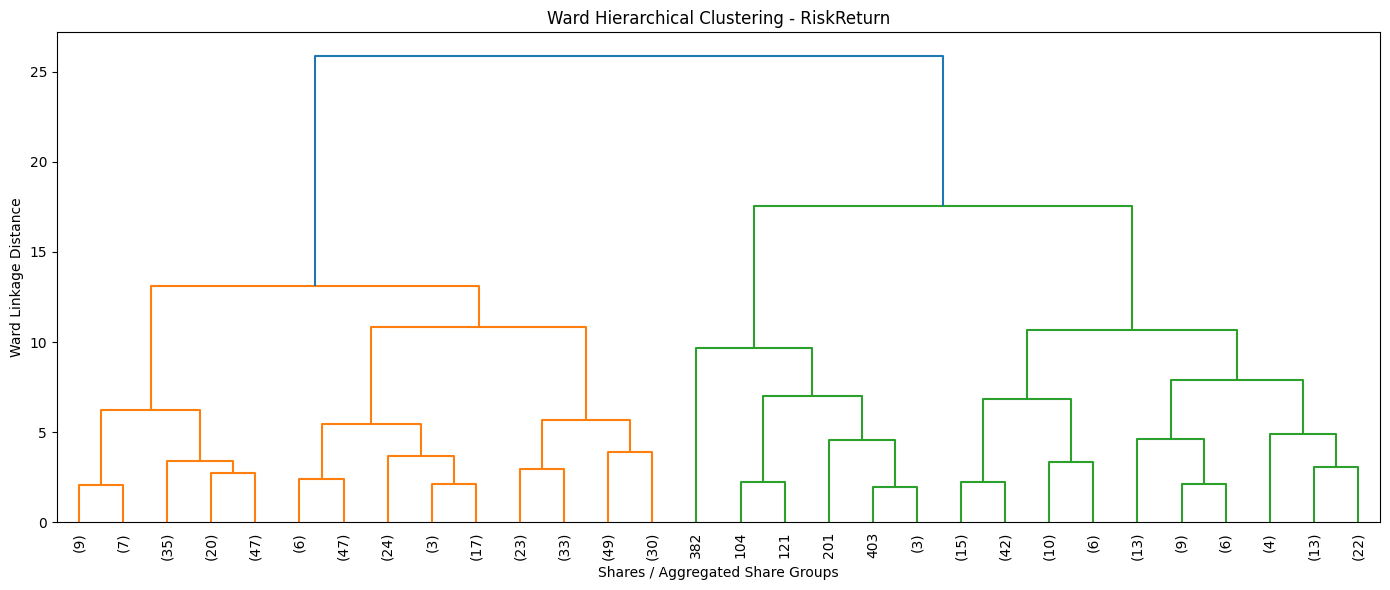

RiskReturn dendrogram saved successfully!


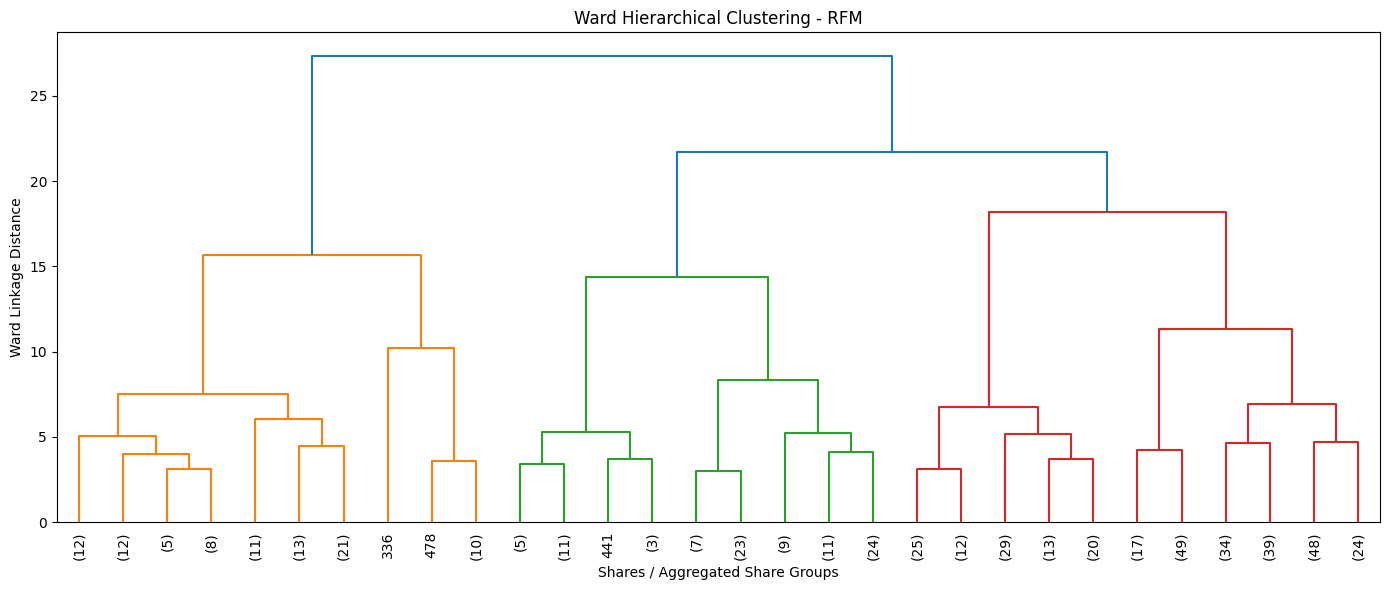

RFM dendrogram saved successfully!

Ward clustering completed!


In [49]:
# TASK 2.2 - WARD AGGLOMERATIVE CLUSTERING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.cluster.hierarchy import linkage, dendrogram

# Main coursework folder
project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

results_dir = project_dir / "results"
figures_dir = project_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

# Reload saved feature matrices
# This also works after a Colab runtime restart

risk_scaled = pd.read_csv(
    results_dir / "risk_scaled.csv",
    index_col="Ticker"
)

rfm_scaled = pd.read_csv(
    results_dir / "rfm_scaled.csv",
    index_col="Ticker"
)

# Validate common shares and numeric values
assert risk_scaled.index.equals(rfm_scaled.index)
assert np.isfinite(risk_scaled.to_numpy()).all()
assert np.isfinite(rfm_scaled.to_numpy()).all()

print("Risk-return matrix:", risk_scaled.shape)
print("RFM matrix:", rfm_scaled.shape)

# Prepare two matrices
matrices = {
    "RiskReturn": risk_scaled,
    "RFM": rfm_scaled
}

ward_linkages = {}

for name, matrix in matrices.items():

    # Ward hierarchical clustering
    Z = linkage(
        matrix.to_numpy(),
        method="ward",
        metric="euclidean"
    )

    ward_linkages[name] = Z

    # Generate dendrogram
    plt.figure(figsize=(14, 6))

    dendrogram(
        Z,
        truncate_mode="lastp",
        p=30,
        show_leaf_counts=True,
        leaf_rotation=90
    )

    plt.title(
        f"Ward Hierarchical Clustering - {name}"
    )

    plt.xlabel("Shares / Aggregated Share Groups")
    plt.ylabel("Ward Linkage Distance")

    plt.tight_layout()

    # Save figure
    plt.savefig(
        figures_dir / f"ward_{name}_dendrogram.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"{name} dendrogram saved successfully!")

print("\nWard clustering completed!")

In [50]:
# TASK 2.2 - WARD CLUSTER EVALUATION

from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score

ward_results = []

for name, matrix in matrices.items():

    Z = ward_linkages[name]

    for k in range(2, 9):

        labels = fcluster(
            Z,
            t=k,
            criterion="maxclust"
        )

        actual_clusters = len(np.unique(labels))

        if actual_clusters < 2:
            continue

        score = silhouette_score(
            matrix.to_numpy(),
            labels
        )

        cluster_sizes = (
            pd.Series(labels)
            .value_counts()
            .sort_index()
        )

        ward_results.append({
            "Matrix": name,
            "RequestedK": k,
            "ActualClusters": actual_clusters,
            "Silhouette": score,
            "SmallestCluster": int(cluster_sizes.min()),
            "LargestCluster": int(cluster_sizes.max()),
            "ClusterSizes": str(cluster_sizes.to_dict())
        })

ward_evaluation = pd.DataFrame(ward_results)

print("WARD CLUSTER EVALUATION")
print("-----------------------")

print("\nRISK-RETURN RESULTS:")
display(
    ward_evaluation[
        ward_evaluation["Matrix"] == "RiskReturn"
    ]
)

print("\nRFM RESULTS:")
display(
    ward_evaluation[
        ward_evaluation["Matrix"] == "RFM"
    ]
)

ward_evaluation.to_csv(
    results_dir / "ward_cluster_evaluation.csv",
    index=False
)

print("\nWard evaluation saved successfully!")

WARD CLUSTER EVALUATION
-----------------------

RISK-RETURN RESULTS:


,Matrix,RequestedK,ActualClusters,Silhouette,SmallestCluster,LargestCluster,ClusterSizes
0,RiskReturn,2,2,0.399833,148,350,"{1: 350, 2: 148}"
1,RiskReturn,3,3,0.382498,8,350,"{1: 350, 2: 8, 3: 140}"
2,RiskReturn,4,4,0.250147,8,232,"{1: 118, 2: 232, 3: 8, 4: 140}"
3,RiskReturn,5,5,0.259250,8,140,"{1: 118, 2: 97, 3: 135, 4: 8, 5: 140}"
4,RiskReturn,6,6,0.281736,8,135,"{1: 118, 2: 97, 3: 135, 4: 8, 5: 73, 6: 67}"
5,RiskReturn,7,7,0.283119,1,135,"{1: 118, 2: 97, 3: 135, 4: 7, 5: 1, 6: 73, 7: 67}"
6,RiskReturn,8,8,0.292828,1,135,"{1: 118, 2: 97, 3: 135, 4: 7, 5: 1, 6: 73, 7: ..."



RFM RESULTS:


,Matrix,RequestedK,ActualClusters,Silhouette,SmallestCluster,LargestCluster,ClusterSizes
7,RFM,2,2,0.358679,94,404,"{1: 94, 2: 404}"
8,RFM,3,3,0.316000,94,310,"{1: 94, 2: 94, 3: 310}"
9,RFM,4,4,0.287608,94,211,"{1: 94, 2: 94, 3: 99, 4: 211}"
10,RFM,5,5,0.310284,12,211,"{1: 82, 2: 12, 3: 94, 4: 99, 5: 211}"
11,RFM,6,6,0.318334,12,211,"{1: 82, 2: 12, 3: 20, 4: 74, 5: 99, 6: 211}"
12,RFM,7,7,0.306113,12,145,"{1: 82, 2: 12, 3: 20, 4: 74, 5: 99, 6: 66, 7: ..."
13,RFM,8,8,0.307970,1,145,"{1: 82, 2: 11, 3: 1, 4: 20, 5: 74, 6: 99, 7: 6..."



Ward evaluation saved successfully!


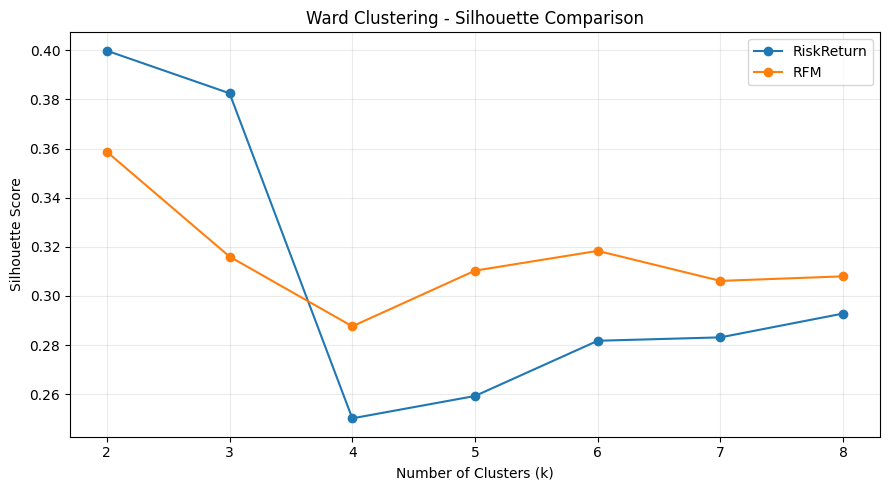

Silhouette comparison chart saved!


In [51]:
# Compare silhouette scores visually

plt.figure(figsize=(9, 5))

for name in ["RiskReturn", "RFM"]:

    subset = ward_evaluation[
        ward_evaluation["Matrix"] == name
    ]

    plt.plot(
        subset["RequestedK"],
        subset["Silhouette"],
        marker="o",
        label=name
    )

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Ward Clustering - Silhouette Comparison")

plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    figures_dir / "ward_silhouette_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Silhouette comparison chart saved!")

In [52]:
# TASK 2.2 - WARD CLUSTER PROFILES

import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/CRM_CWK1_2026")
results_dir = project_dir / "results"

# Reload source features
features = pd.read_csv(
    results_dir / "final_stock_features.csv"
).set_index("Ticker")

risk_scaled = pd.read_csv(
    results_dir / "risk_scaled.csv",
    index_col="Ticker"
)

rfm_scaled = pd.read_csv(
    results_dir / "rfm_scaled.csv",
    index_col="Ticker"
)

# Align all datasets to identical share order
risk_scaled = risk_scaled.loc[features.index]
rfm_scaled = rfm_scaled.loc[features.index]

matrices = {
    "RiskReturn": risk_scaled,
    "RFM": rfm_scaled
}

profile_results = []

for name, matrix in matrices.items():

    Z = linkage(
        matrix.to_numpy(),
        method="ward",
        metric="euclidean"
    )

    for k in [2, 3]:

        labels = fcluster(
            Z,
            t=k,
            criterion="maxclust"
        )

        temp = features.copy()
        temp["Cluster"] = labels

        profiles = temp.groupby("Cluster").agg(
            Shares=("MeanWeeklyReturn", "size"),
            MeanWeeklyReturn=("MeanWeeklyReturn", "mean"),
            MeanBeta=("WeeklyBeta", "mean"),
            MeanRecency=("Recency", "mean"),
            MeanFrequency=("Frequency", "mean"),
            MeanMonetaryUSD=("MonetaryUSD", "mean")
        ).reset_index()

        profiles["MeanWeeklyReturnPct"] = (
            profiles["MeanWeeklyReturn"] * 100
        )

        profiles["MeanMonetaryBillion"] = (
            profiles["MeanMonetaryUSD"] / 1e9
        )

        profiles["Matrix"] = name
        profiles["K"] = k

        profile_results.append(profiles)

ward_profiles = pd.concat(
    profile_results,
    ignore_index=True
)

# Save evidence
ward_profiles.to_csv(
    results_dir / "ward_candidate_profiles.csv",
    index=False
)

for name in ["RiskReturn", "RFM"]:

    print(f"\n{name.upper()} - WARD PROFILES")

    display(
        ward_profiles[
            ward_profiles["Matrix"] == name
        ][[
            "K", "Cluster", "Shares",
            "MeanWeeklyReturnPct",
            "MeanBeta",
            "MeanRecency",
            "MeanFrequency",
            "MeanMonetaryBillion"
        ]].round(3)
    )

print("\nWard candidate profiles saved!")


RISKRETURN - WARD PROFILES


,K,Cluster,Shares,MeanWeeklyReturnPct,MeanBeta,MeanRecency,MeanFrequency,MeanMonetaryBillion
0,2,1,350,0.206,0.795,18.969,2.909,22.113
1,2,2,148,0.536,1.432,24.155,3.230,81.000
2,3,1,350,0.206,0.795,18.969,2.909,22.113
3,3,2,8,1.743,2.369,55.375,3.375,312.194
4,3,3,140,0.467,1.379,22.371,3.221,67.789



RFM - WARD PROFILES


,K,Cluster,Shares,MeanWeeklyReturnPct,MeanBeta,MeanRecency,MeanFrequency,MeanMonetaryBillion
5,2,1,94,0.306,1.019,55.532,2.074,45.650
6,2,2,404,0.304,0.976,12.361,3.220,38.209
7,3,1,94,0.306,1.019,55.532,2.074,45.650
8,3,2,94,0.394,1.105,15.628,4.840,90.387
9,3,3,310,0.277,0.937,11.371,2.729,22.387



Ward candidate profiles saved!


### K-means clustering


In [53]:
# TASK 2.3 - K-MEANS CLUSTERING

import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_results = []

for name, matrix in matrices.items():

    X = matrix.to_numpy()

    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = model.fit_predict(X)

        score = silhouette_score(
            X,
            labels
        )

        sizes = (
            pd.Series(labels)
            .value_counts()
            .sort_index()
        )

        kmeans_results.append({
            "Matrix": name,
            "K": k,
            "Silhouette": score,
            "Inertia": model.inertia_,
            "SmallestCluster": int(sizes.min()),
            "LargestCluster": int(sizes.max()),
            "ClusterSizes": str(sizes.to_dict())
        })

kmeans_evaluation = pd.DataFrame(
    kmeans_results
)

print("K-MEANS CLUSTER EVALUATION")
print("-------------------------")

print("\nRISK-RETURN RESULTS:")
display(
    kmeans_evaluation[
        kmeans_evaluation["Matrix"] == "RiskReturn"
    ].round(4)
)

print("\nRFM RESULTS:")
display(
    kmeans_evaluation[
        kmeans_evaluation["Matrix"] == "RFM"
    ].round(4)
)

# Save results
kmeans_evaluation.to_csv(
    results_dir / "kmeans_cluster_evaluation.csv",
    index=False
)

print("\nK-means evaluation saved successfully!")

K-MEANS CLUSTER EVALUATION
-------------------------

RISK-RETURN RESULTS:


,Matrix,K,Silhouette,Inertia,SmallestCluster,LargestCluster,ClusterSizes
0,RiskReturn,2,0.3998,658.3829,148,350,"{0: 350, 1: 148}"
1,RiskReturn,3,0.3496,497.9273,9,281,"{0: 281, 1: 208, 2: 9}"
2,RiskReturn,4,0.3377,386.2196,8,192,"{0: 176, 1: 8, 2: 122, 3: 192}"
3,RiskReturn,5,0.3464,318.2242,7,176,"{0: 139, 1: 60, 2: 7, 3: 176, 4: 116}"
4,RiskReturn,6,0.3373,268.9945,2,154,"{0: 132, 1: 154, 2: 58, 3: 27, 4: 2, 5: 125}"
5,RiskReturn,7,0.3360,224.9926,2,147,"{0: 110, 1: 43, 2: 57, 3: 147, 4: 2, 5: 7, 6: ..."
6,RiskReturn,8,0.3282,195.0138,2,128,"{0: 89, 1: 50, 2: 7, 3: 105, 4: 77, 5: 40, 6: ..."



RFM RESULTS:


,Matrix,K,Silhouette,Inertia,SmallestCluster,LargestCluster,ClusterSizes
7,RFM,2,0.4190,1094.0497,72,426,"{0: 72, 1: 426}"
8,RFM,3,0.3245,818.2375,65,276,"{0: 276, 1: 65, 2: 157}"
9,RFM,4,0.3401,625.2396,61,216,"{0: 123, 1: 98, 2: 216, 3: 61}"
10,RFM,5,0.3568,528.6987,11,202,"{0: 202, 1: 11, 2: 70, 3: 124, 4: 91}"
11,RFM,6,0.3468,447.4880,11,144,"{0: 107, 1: 11, 2: 72, 3: 120, 4: 44, 5: 144}"
12,RFM,7,0.3486,396.2788,1,144,"{0: 120, 1: 44, 2: 11, 3: 144, 4: 107, 5: 1, 6..."
13,RFM,8,0.3470,354.6817,1,142,"{0: 68, 1: 108, 2: 14, 3: 19, 4: 63, 5: 142, 6..."



K-means evaluation saved successfully!


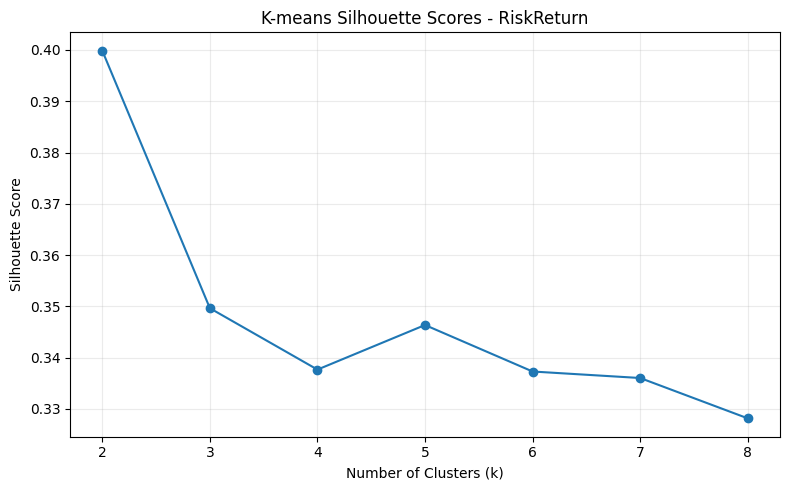

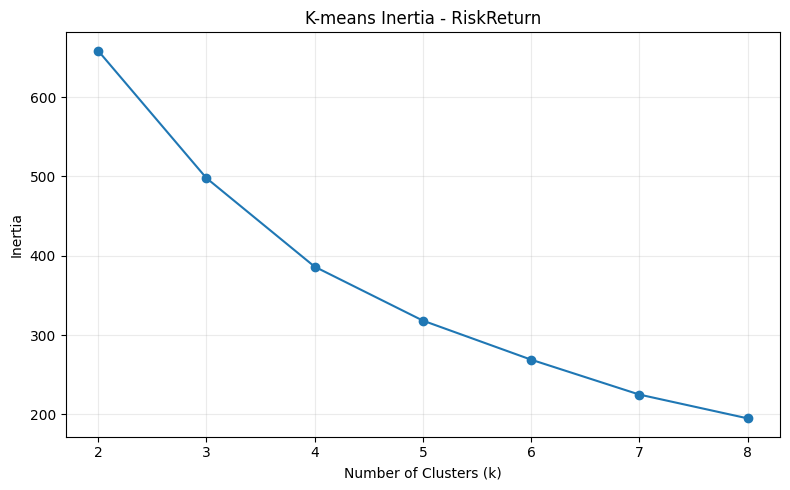

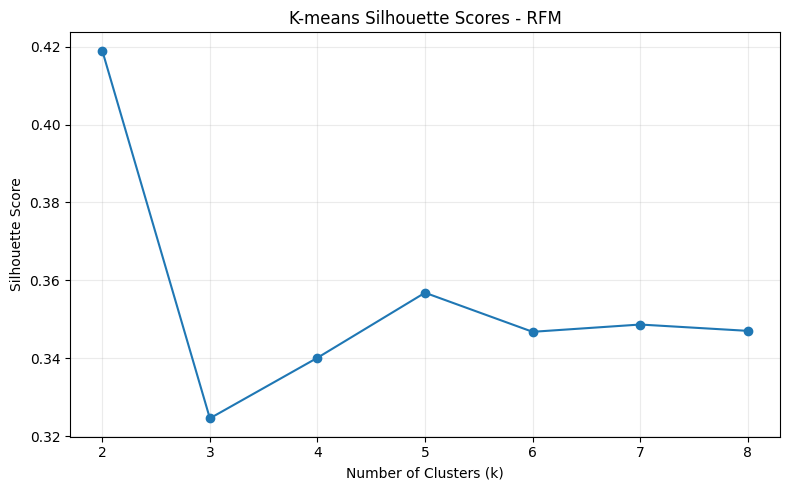

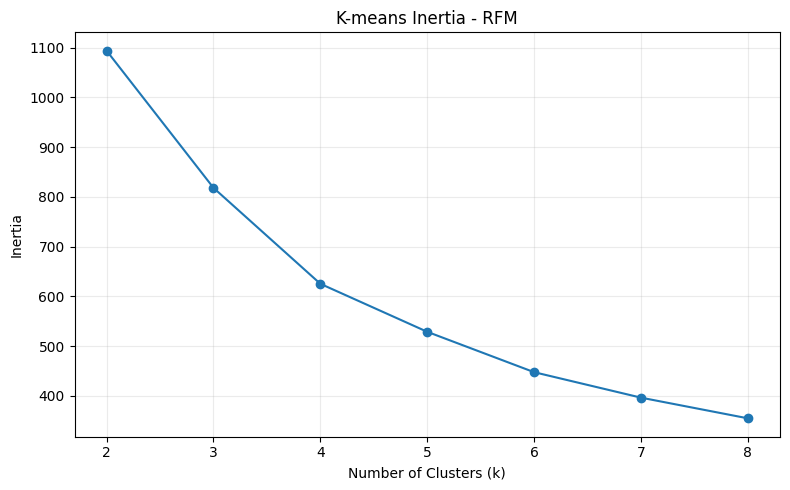

K-means evaluation charts saved successfully!


In [54]:
# TASK 2.3 - K-MEANS EVALUATION CHARTS

import matplotlib.pyplot as plt

figures_dir = project_dir / "figures"
figures_dir.mkdir(exist_ok=True)

for name in ["RiskReturn", "RFM"]:

    subset = kmeans_evaluation[
        kmeans_evaluation["Matrix"] == name
    ]

    # Silhouette chart
    plt.figure(figsize=(8, 5))

    plt.plot(
        subset["K"],
        subset["Silhouette"],
        marker="o"
    )

    plt.title(f"K-means Silhouette Scores - {name}")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Silhouette Score")
    plt.xticks(range(2, 9))
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        figures_dir / f"kmeans_{name}_silhouette.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # Inertia chart
    plt.figure(figsize=(8, 5))

    plt.plot(
        subset["K"],
        subset["Inertia"],
        marker="o"
    )

    plt.title(f"K-means Inertia - {name}")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia")
    plt.xticks(range(2, 9))
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        figures_dir / f"kmeans_{name}_inertia.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("K-means evaluation charts saved successfully!")

### Cluster assignments, profiles and visualisations


In [55]:
# TASK 2.4 - FINAL CLUSTER ASSIGNMENTS

import pandas as pd
import numpy as np

from pathlib import Path
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)
results_dir = project_dir / "results"

# Reload final features
features = pd.read_csv(
    results_dir / "final_stock_features.csv"
).set_index("Ticker")

risk_scaled = pd.read_csv(
    results_dir / "risk_scaled.csv",
    index_col="Ticker"
).loc[features.index]

rfm_scaled = pd.read_csv(
    results_dir / "rfm_scaled.csv",
    index_col="Ticker"
).loc[features.index]

# Selected cluster counts
k_risk = 2
k_rfm = 2

# WARD: Risk-return
ward_risk = fcluster(
    linkage(risk_scaled, method="ward"),
    t=k_risk,
    criterion="maxclust"
)

# WARD: RFM
ward_rfm = fcluster(
    linkage(rfm_scaled, method="ward"),
    t=k_rfm,
    criterion="maxclust"
)

# K-MEANS: Risk-return
km_risk = KMeans(
    n_clusters=k_risk,
    random_state=42,
    n_init=20
).fit_predict(risk_scaled) + 1

# K-MEANS: RFM
km_rfm = KMeans(
    n_clusters=k_rfm,
    random_state=42,
    n_init=20
).fit_predict(rfm_scaled) + 1

# Combine all four solutions
clusters = pd.DataFrame(
    {
        "Ward_RiskReturn": ward_risk,
        "KMeans_RiskReturn": km_risk,
        "Ward_RFM": ward_rfm,
        "KMeans_RFM": km_rfm
    },
    index=features.index
)

clusters.index.name = "Ticker"

# Validate
assert len(clusters) == 498
assert clusters.notna().all().all()
assert clusters.index.is_unique

# Combine features and cluster assignments
final_clusters = features.join(clusters)

# Save complete table
final_clusters.to_csv(
    results_dir / "final_stock_clusters.csv"
)

print("FINAL CLUSTER ASSIGNMENTS")
print("-------------------------")

print("Total shares:", len(final_clusters))

for column in clusters.columns:
    print(f"\n{column}")
    print(clusters[column].value_counts().sort_index())

# Compare Ward and K-means memberships
ari_risk = adjusted_rand_score(
    clusters["Ward_RiskReturn"],
    clusters["KMeans_RiskReturn"]
)

ari_rfm = adjusted_rand_score(
    clusters["Ward_RFM"],
    clusters["KMeans_RFM"]
)

print("\nWARD vs K-MEANS AGREEMENT")
print("Risk-return ARI:", round(ari_risk, 4))
print("RFM ARI:", round(ari_rfm, 4))

print("\nSample assignments:")
display(clusters.head(10))

print("\nFinal cluster assignments saved!")

FINAL CLUSTER ASSIGNMENTS
-------------------------
Total shares: 498

Ward_RiskReturn
Ward_RiskReturn
1    350
2    148
Name: count, dtype: int64

KMeans_RiskReturn
KMeans_RiskReturn
1    350
2    148
Name: count, dtype: int64

Ward_RFM
Ward_RFM
1     94
2    404
Name: count, dtype: int64

KMeans_RFM
KMeans_RFM
1     72
2    426
Name: count, dtype: int64

WARD vs K-MEANS AGREEMENT
Risk-return ARI: 0.9349
RFM ARI: 0.7537

Sample assignments:


,Ward_RiskReturn,KMeans_RiskReturn,Ward_RFM,KMeans_RFM
Ticker,,,,
A,1,1,2,2
AAPL,2,2,2,2
ABBV,1,1,2,2
ABNB,2,2,2,2
ABT,1,1,2,2
ACGL,1,1,2,2
ACN,1,1,2,2
ADBE,2,2,2,2
ADI,1,1,1,1



Final cluster assignments saved!


In [56]:
# TASK 2.4 - FINAL CLUSTER PROFILES

profile_tables = []

for model_name in clusters.columns:

    temp = final_clusters.copy()

    temp["Cluster"] = clusters[model_name]

    profile = temp.groupby("Cluster").agg(
        Shares=("MeanWeeklyReturn", "size"),
        MeanWeeklyReturn=("MeanWeeklyReturn", "mean"),
        MeanBeta=("WeeklyBeta", "mean"),
        MeanRecency=("Recency", "mean"),
        MeanFrequency=("Frequency", "mean"),
        MeanMonetaryUSD=("MonetaryUSD", "mean"),
        MedianMonetaryUSD=("MonetaryUSD", "median")
    ).reset_index()

    # Convert to interpretable units
    profile["MeanWeeklyReturnPct"] = (
        profile["MeanWeeklyReturn"] * 100
    )

    profile["MeanMonetaryBillion"] = (
        profile["MeanMonetaryUSD"] / 1e9
    )

    profile["MedianMonetaryBillion"] = (
        profile["MedianMonetaryUSD"] / 1e9
    )

    profile["Model"] = model_name

    profile_tables.append(profile)

cluster_profiles = pd.concat(
    profile_tables,
    ignore_index=True
)

# Display each clustering solution
for model_name in clusters.columns:

    print(f"\nCLUSTER PROFILE: {model_name}")

    display(
        cluster_profiles[
            cluster_profiles["Model"] == model_name
        ][[
            "Cluster",
            "Shares",
            "MeanWeeklyReturnPct",
            "MeanBeta",
            "MeanRecency",
            "MeanFrequency",
            "MeanMonetaryBillion",
            "MedianMonetaryBillion"
        ]].round(3)
    )

# Save complete profiles
cluster_profiles.to_csv(
    results_dir / "final_cluster_profiles.csv",
    index=False
)

print("\nAll four cluster profiles saved!")


CLUSTER PROFILE: Ward_RiskReturn


,Cluster,Shares,MeanWeeklyReturnPct,MeanBeta,MeanRecency,MeanFrequency,MeanMonetaryBillion,MedianMonetaryBillion
0,1,350,0.206,0.795,18.969,2.909,22.113,14.736
1,2,148,0.536,1.432,24.155,3.230,81.000,26.884



CLUSTER PROFILE: KMeans_RiskReturn


,Cluster,Shares,MeanWeeklyReturnPct,MeanBeta,MeanRecency,MeanFrequency,MeanMonetaryBillion,MedianMonetaryBillion
2,1,350,0.202,0.798,19.171,2.923,22.326,14.736
3,2,148,0.546,1.426,23.676,3.196,80.497,26.884



CLUSTER PROFILE: Ward_RFM


,Cluster,Shares,MeanWeeklyReturnPct,MeanBeta,MeanRecency,MeanFrequency,MeanMonetaryBillion,MedianMonetaryBillion
4,1,94,0.306,1.019,55.532,2.074,45.650,20.950
5,2,404,0.304,0.976,12.361,3.220,38.209,15.473



CLUSTER PROFILE: KMeans_RFM


,Cluster,Shares,MeanWeeklyReturnPct,MeanBeta,MeanRecency,MeanFrequency,MeanMonetaryBillion,MedianMonetaryBillion
6,1,72,0.327,1.027,62.486,1.847,80.601,23.084
7,2,426,0.300,0.977,13.415,3.200,32.686,15.570



All four cluster profiles saved!


RFM PCA explained variance:
PC1: 45.66 %
PC2: 33.9 %
Total: 79.56 %


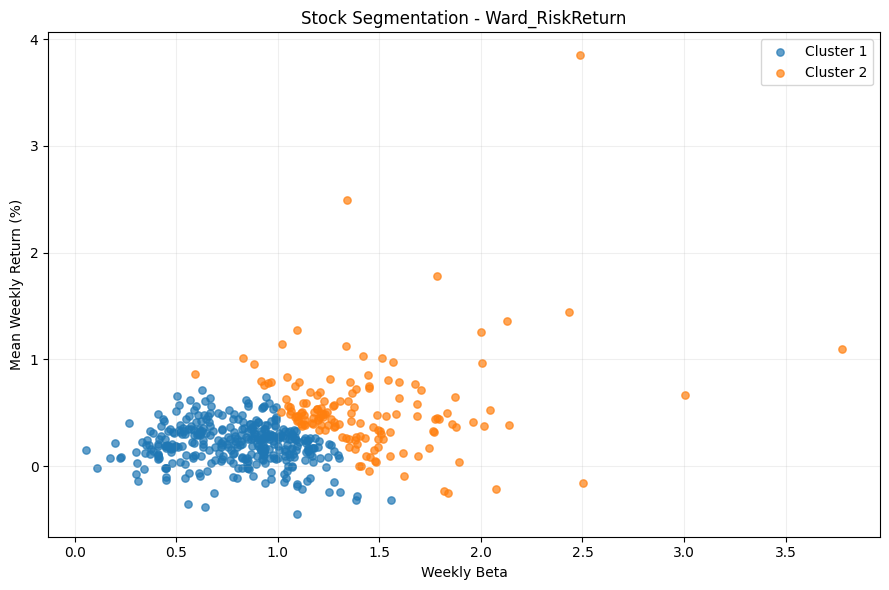

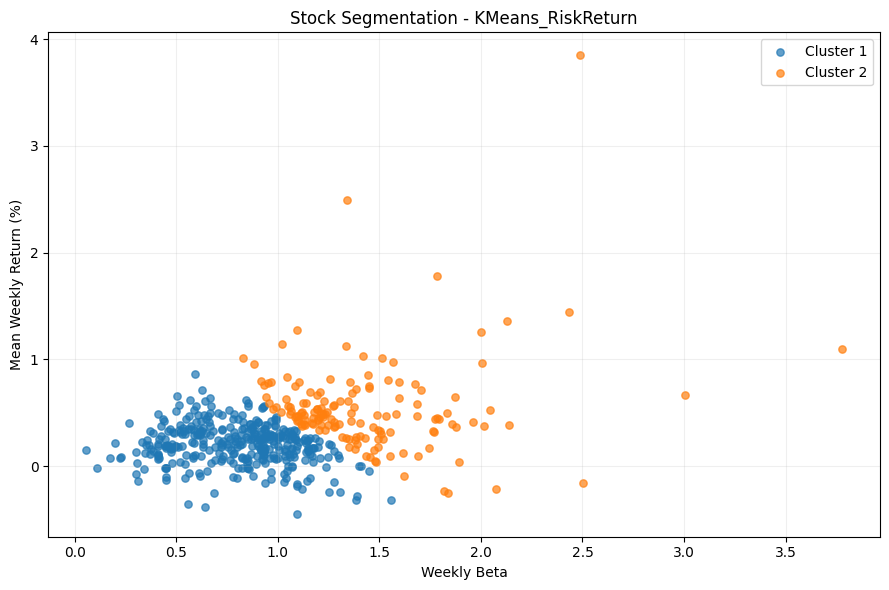

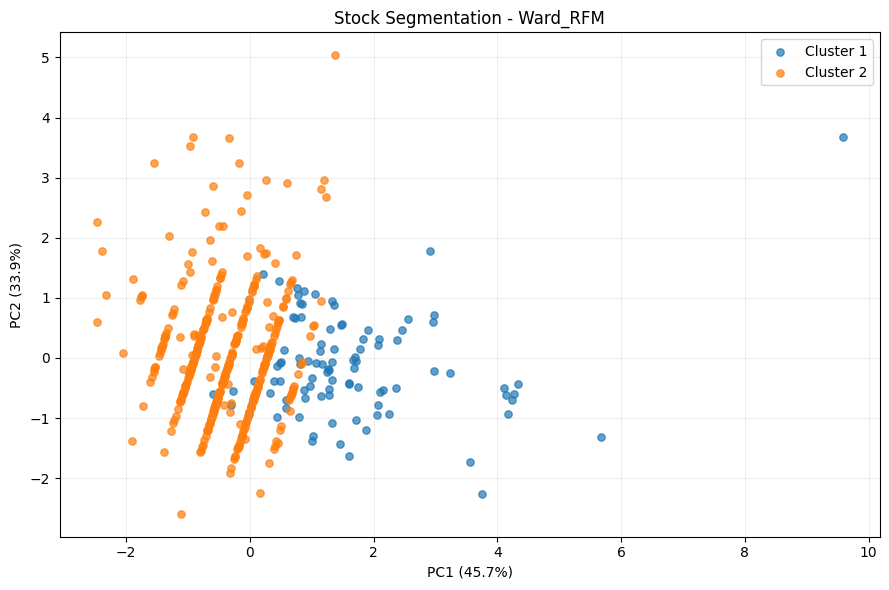

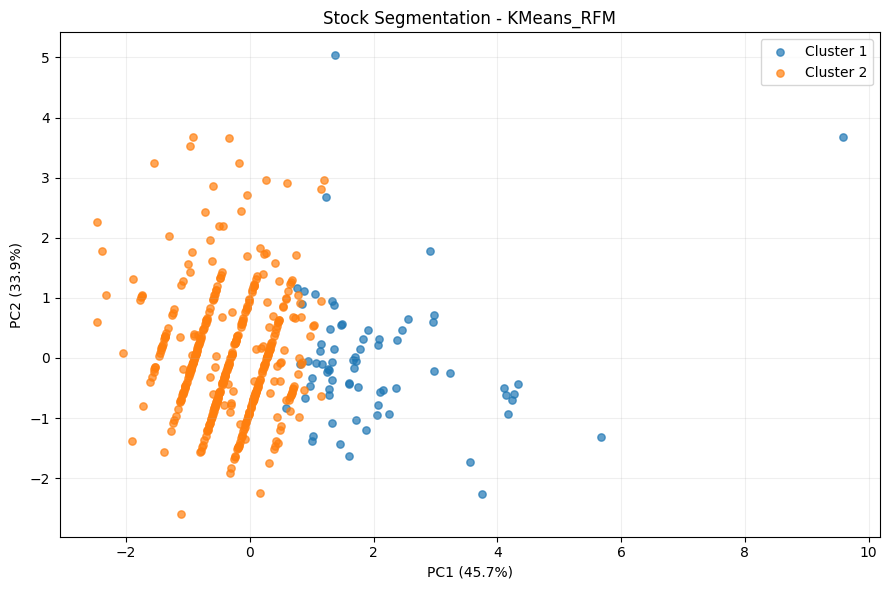

All four cluster visualisations saved!


In [57]:
# TASK 2.4 - CLUSTER VISUALISATIONS

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

figures_dir = project_dir / "figures"
figures_dir.mkdir(exist_ok=True)

# PCA for the three-dimensional RFM matrix
pca = PCA(n_components=2)

rfm_coordinates = pca.fit_transform(rfm_scaled)

explained = pca.explained_variance_ratio_

print("RFM PCA explained variance:")
print("PC1:", round(explained[0] * 100, 2), "%")
print("PC2:", round(explained[1] * 100, 2), "%")
print("Total:", round(explained.sum() * 100, 2), "%")

for model_name in clusters.columns:

    labels = clusters[model_name]

    if "RiskReturn" in model_name:

        x = features["WeeklyBeta"].to_numpy()
        y = features["MeanWeeklyReturn"].to_numpy() * 100

        xlabel = "Weekly Beta"
        ylabel = "Mean Weekly Return (%)"

    else:

        x = rfm_coordinates[:, 0]
        y = rfm_coordinates[:, 1]

        xlabel = f"PC1 ({explained[0]*100:.1f}%)"
        ylabel = f"PC2 ({explained[1]*100:.1f}%)"

    plt.figure(figsize=(9, 6))

    for cluster_id in sorted(labels.unique()):

        mask = labels.to_numpy() == cluster_id

        plt.scatter(
            x[mask],
            y[mask],
            label=f"Cluster {cluster_id}",
            alpha=0.7,
            s=28
        )

    plt.title(f"Stock Segmentation - {model_name}")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        figures_dir / f"{model_name}_clusters.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("All four cluster visualisations saved!")

### RFM correlation and Monetary sensitivity


TASK 2.5.1 - RFM CORRELATION
----------------------------
Number of shares: 498


,Recency,Frequency,LogMonetary
Recency,1.0000,-0.3402,0.1647
Frequency,-0.3402,1.0000,0.0219
LogMonetary,0.1647,0.0219,1.0000


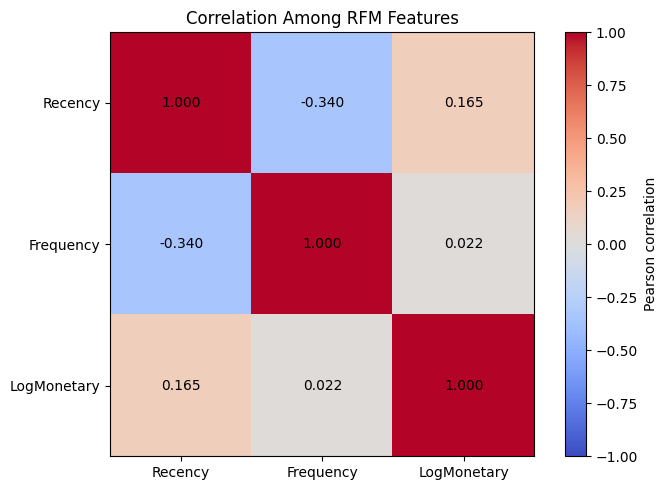

Correlation analysis saved successfully!


In [58]:
# TASK 2.5.1 - RFM CORRELATION ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

results_dir = project_dir / "results"
figures_dir = project_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

# Load final features
features = pd.read_csv(
    results_dir / "final_stock_features.csv"
).set_index("Ticker")

# Prepare RFM features
rfm_correlation_data = pd.DataFrame(
    {
        "Recency": features["Recency"],
        "Frequency": features["Frequency"],
        "LogMonetary": np.log1p(
            features["MonetaryUSD"]
        )
    }
)

# Check valid data
assert np.isfinite(
    rfm_correlation_data.to_numpy()
).all()

# Pearson correlation
rfm_corr = rfm_correlation_data.corr(
    method="pearson"
)

print("TASK 2.5.1 - RFM CORRELATION")
print("----------------------------")

print("Number of shares:", len(rfm_correlation_data))

display(rfm_corr.round(4))

# Save correlation table
rfm_corr.to_csv(
    results_dir / "rfm_correlation_matrix.csv"
)

# Draw correlation heatmap
fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(
    rfm_corr.to_numpy(),
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(3))
ax.set_yticks(range(3))

ax.set_xticklabels(rfm_corr.columns)
ax.set_yticklabels(rfm_corr.index)

for i in range(3):
    for j in range(3):
        ax.text(
            j, i,
            f"{rfm_corr.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

plt.colorbar(im, ax=ax, label="Pearson correlation")

plt.title("Correlation Among RFM Features")
plt.tight_layout()

plt.savefig(
    figures_dir / "rfm_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correlation analysis saved successfully!")

In [59]:
# TASK 2.5.2 - REMOVE MONETARY SENSITIVITY TEST

import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.optimize import linear_sum_assignment

# Load original features
features = pd.read_csv(
    results_dir / "final_stock_features.csv"
).set_index("Ticker")

# Load original four clustering assignments
original_clusters = pd.read_csv(
    results_dir / "final_stock_clusters.csv"
).set_index("Ticker")

# Align identical share sets
original_clusters = original_clusters.loc[features.index]

assert features.index.equals(original_clusters.index)
assert features.index.is_unique

# Original Ward RFM membership
original_labels = original_clusters["Ward_RFM"]

# Reduced matrix: Recency and Frequency only
reduced_rfm = features[
    ["Recency", "Frequency"]
].copy()

# Standardise reduced matrix afresh
scaler = StandardScaler()

reduced_scaled = pd.DataFrame(
    scaler.fit_transform(reduced_rfm),
    index=reduced_rfm.index,
    columns=reduced_rfm.columns
)

# Apply Ward clustering with k = 2
Z_reduced = linkage(
    reduced_scaled.to_numpy(),
    method="ward",
    metric="euclidean"
)

reduced_labels = pd.Series(
    fcluster(
        Z_reduced,
        t=2,
        criterion="maxclust"
    ),
    index=features.index,
    name="Ward_RF_Only"
)

# Verify cluster count
assert reduced_labels.nunique() == 2

# Compare original and reduced cluster assignments
ari = adjusted_rand_score(
    original_labels,
    reduced_labels
)

print("MONETARY REMOVAL SENSITIVITY TEST")
print("---------------------------------")

print("Shares compared:", len(features))
print("Selected cluster count:", 2)
print("Adjusted Rand Index:", round(ari, 4))

print("\nOriginal Ward RFM cluster sizes:")
display(original_labels.value_counts().sort_index())

print("\nReduced Ward R-F cluster sizes:")
display(reduced_labels.value_counts().sort_index())

# Initial membership comparison
comparison = pd.crosstab(
    original_labels,
    reduced_labels
)

print("\nOriginal vs reduced memberships:")
display(comparison)

# Match reduced cluster labels to original labels
# Cluster labels are arbitrary, so this is for
# interpreting switches, not for calculating ARI

rows, cols = linear_sum_assignment(
    -comparison.to_numpy()
)

label_mapping = {
    comparison.columns[c]: comparison.index[r]
    for r, c in zip(rows, cols)
}

aligned_reduced_labels = reduced_labels.map(label_mapping)

# Count genuine membership changes
changed = (
    original_labels != aligned_reduced_labels
)

print("\nShares changing cluster membership:",
      int(changed.sum()))

print("Membership change percentage:",
      round(changed.mean() * 100, 2), "%")

# Create and save comparison table
sensitivity_assignments = pd.DataFrame({
    "OriginalWardRFM": original_labels,
    "ReducedWardRF": reduced_labels,
    "ReducedLabelAligned": aligned_reduced_labels,
    "ChangedMembership": changed
})

sensitivity_assignments.to_csv(
    results_dir / "rfm_sensitivity_assignments.csv",
    index_label="Ticker"
)

print("\nMembership comparison saved successfully!")

MONETARY REMOVAL SENSITIVITY TEST
---------------------------------
Shares compared: 498
Selected cluster count: 2
Adjusted Rand Index: 0.9531

Original Ward RFM cluster sizes:


,count
Ward_RFM,
1,94
2,404



Reduced Ward R-F cluster sizes:


,count
Ward_RF_Only,
1,93
2,405



Original vs reduced memberships:


Ward_RF_Only,1,2
Ward_RFM,,
1,91,3
2,2,402



Shares changing cluster membership: 5
Membership change percentage: 1.0 %

Membership comparison saved successfully!


In [60]:
# TASK 2.5.2 - SENSITIVITY CLUSTER PROFILES

# Compare original and reduced Ward profiles

profile_data = features[
    ["Recency", "Frequency", "MonetaryUSD"]
].copy()

profile_data["OriginalWardRFM"] = original_labels
profile_data["ReducedWardRF"] = aligned_reduced_labels

sensitivity_profiles = []

for model in ["OriginalWardRFM", "ReducedWardRF"]:

    summary = profile_data.groupby(model).agg(
        Shares=("MonetaryUSD", "size"),
        MeanRecency=("Recency", "mean"),
        MeanFrequency=("Frequency", "mean"),
        MeanMonetaryUSD=("MonetaryUSD", "mean"),
        MedianMonetaryUSD=("MonetaryUSD", "median")
    ).reset_index()

    summary = summary.rename(
        columns={model: "Cluster"}
    )

    summary["MeanMonetaryBillion"] = (
        summary["MeanMonetaryUSD"] / 1e9
    )

    summary["MedianMonetaryBillion"] = (
        summary["MedianMonetaryUSD"] / 1e9
    )

    summary["Model"] = model

    sensitivity_profiles.append(summary)

sensitivity_profiles = pd.concat(
    sensitivity_profiles,
    ignore_index=True
)

print("RFM SENSITIVITY CLUSTER PROFILES")
print("--------------------------------")

display(
    sensitivity_profiles[
        [
            "Model",
            "Cluster",
            "Shares",
            "MeanRecency",
            "MeanFrequency",
            "MeanMonetaryBillion",
            "MedianMonetaryBillion"
        ]
    ].round(3)
)

# Show examples of shares changing membership
changed_tickers = sensitivity_assignments[
    sensitivity_assignments["ChangedMembership"]
].index.tolist()

print("\nNumber of changed shares:",
      len(changed_tickers))

print("\nSample changed tickers:")
display(
    sensitivity_assignments.loc[
        changed_tickers
    ].head(15)
)

# Save profiles
sensitivity_profiles.to_csv(
    results_dir / "rfm_sensitivity_profiles.csv",
    index=False
)

print("\nSensitivity profiles saved successfully!")

RFM SENSITIVITY CLUSTER PROFILES
--------------------------------


,Model,Cluster,Shares,MeanRecency,MeanFrequency,MeanMonetaryBillion,MedianMonetaryBillion
0,OriginalWardRFM,1,94,55.532,2.074,45.650,20.950
1,OriginalWardRFM,2,404,12.361,3.220,38.209,15.473
2,ReducedWardRF,1,93,56.032,2.054,47.996,21.053
3,ReducedWardRF,2,405,12.353,3.222,37.689,15.457



Number of changed shares: 5

Sample changed tickers:


,OriginalWardRFM,ReducedWardRF,ReducedLabelAligned,ChangedMembership
Ticker,,,,
COIN,2,1,1,True
EFX,2,1,1,True
PPG,1,2,2,True
TKO,1,2,2,True
XYZ,1,2,2,True



Sensitivity profiles saved successfully!


## Task 3 — Sector composition and cross-model analytical evidence


TASK 3.2 - SECTOR COMPOSITION
-----------------------------
Total shares: 498
Number of sectors: 11

SECTOR COMPOSITION: Ward_RiskReturn
Cluster sizes:


,Shares
Ward_RiskReturn,
1,350
2,148


Sector percentages:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RiskReturn,,,,,,,,,,,
1,4.29,7.43,9.14,4.86,16.00,15.43,15.43,6.29,5.14,7.71,8.29
2,4.73,14.19,0.00,2.70,13.51,4.05,18.24,35.14,4.05,2.03,1.35


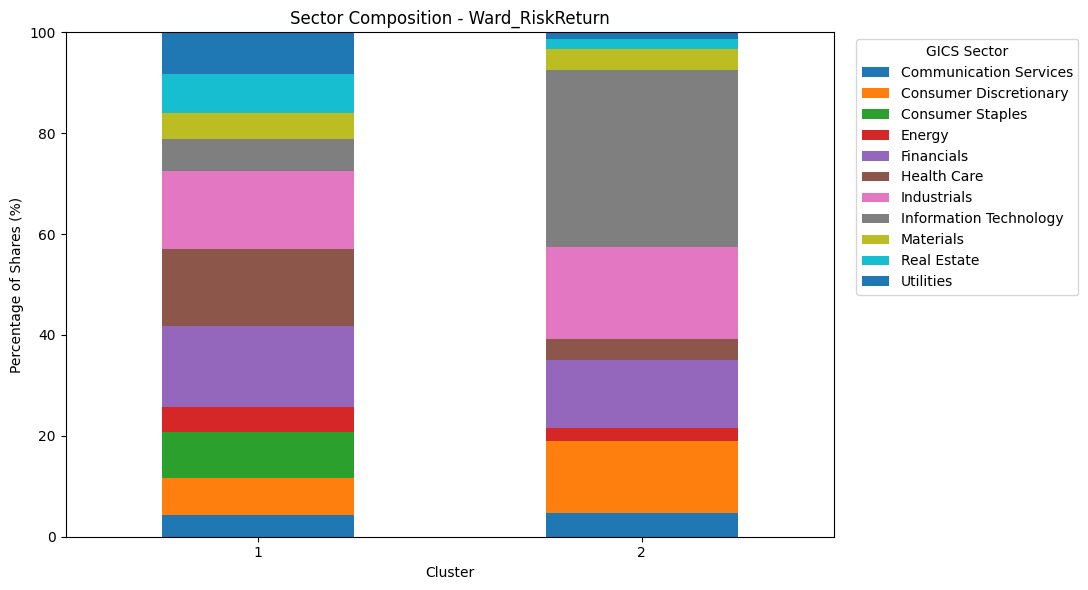


SECTOR COMPOSITION: KMeans_RiskReturn
Cluster sizes:


,Shares
KMeans_RiskReturn,
1,350
2,148


Sector percentages:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RiskReturn,,,,,,,,,,,
1,4.29,7.43,8.86,4.57,16.00,16.57,15.14,6.29,5.14,7.71,8.00
2,4.73,14.19,0.68,3.38,13.51,1.35,18.92,35.14,4.05,2.03,2.03


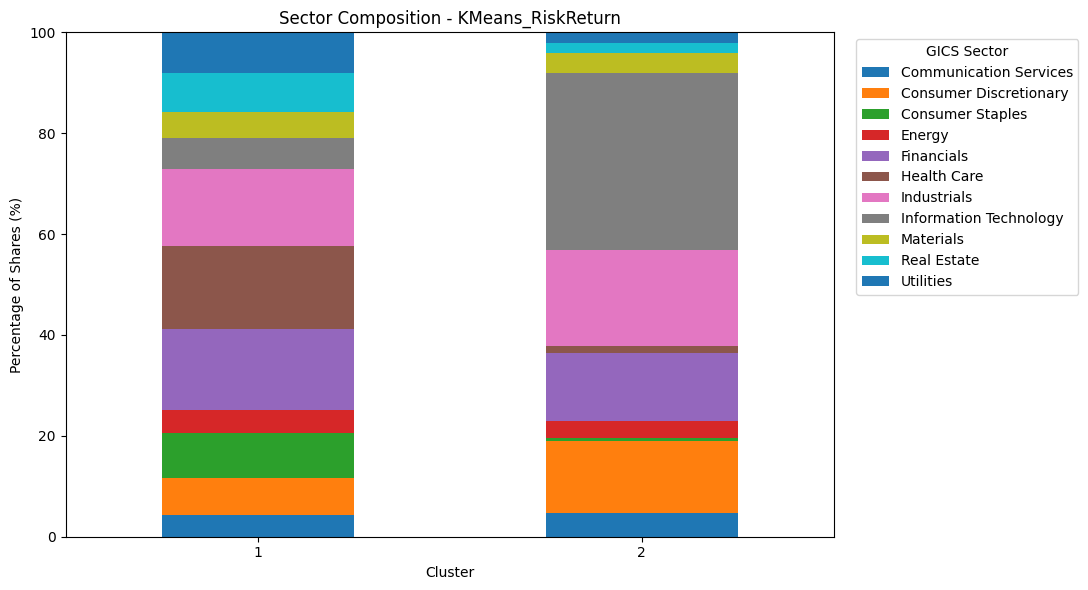


SECTOR COMPOSITION: Ward_RFM
Cluster sizes:


,Shares
Ward_RFM,
1,94
2,404


Sector percentages:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RFM,,,,,,,,,,,
1,4.26,10.64,8.51,2.13,14.89,9.57,9.57,21.28,8.51,0.00,10.64
2,4.46,9.16,5.94,4.70,15.35,12.62,17.82,13.37,3.96,7.43,5.20


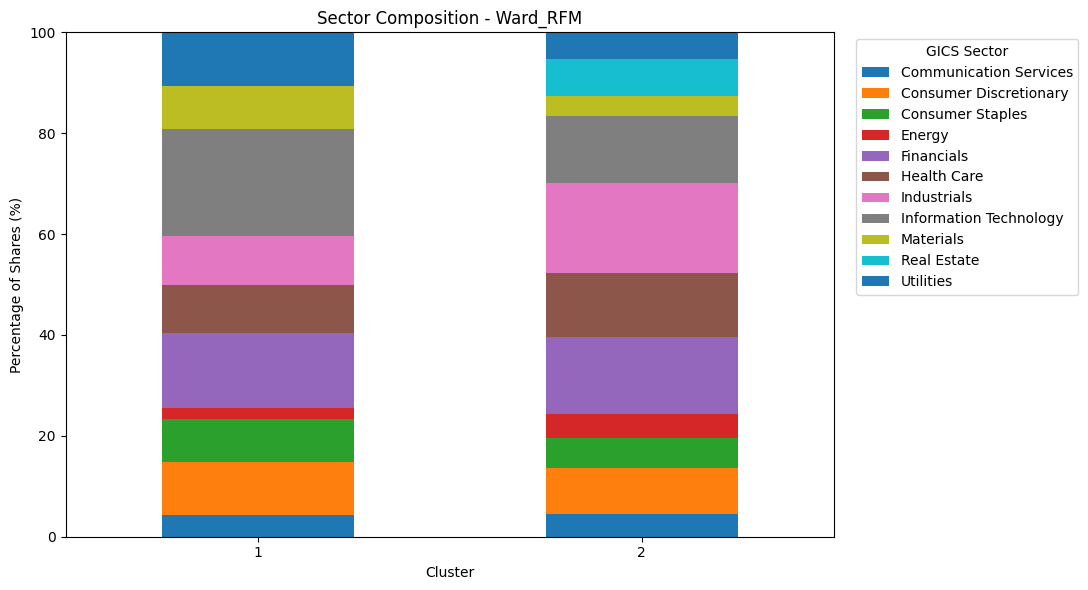


SECTOR COMPOSITION: KMeans_RFM
Cluster sizes:


,Shares
KMeans_RFM,
1,72
2,426


Sector percentages:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM,,,,,,,,,,,
1,2.78,11.11,6.94,1.39,16.67,11.11,6.94,20.83,8.33,0.00,13.89
2,4.69,9.15,6.34,4.69,15.02,12.21,17.84,13.85,4.23,7.04,4.93


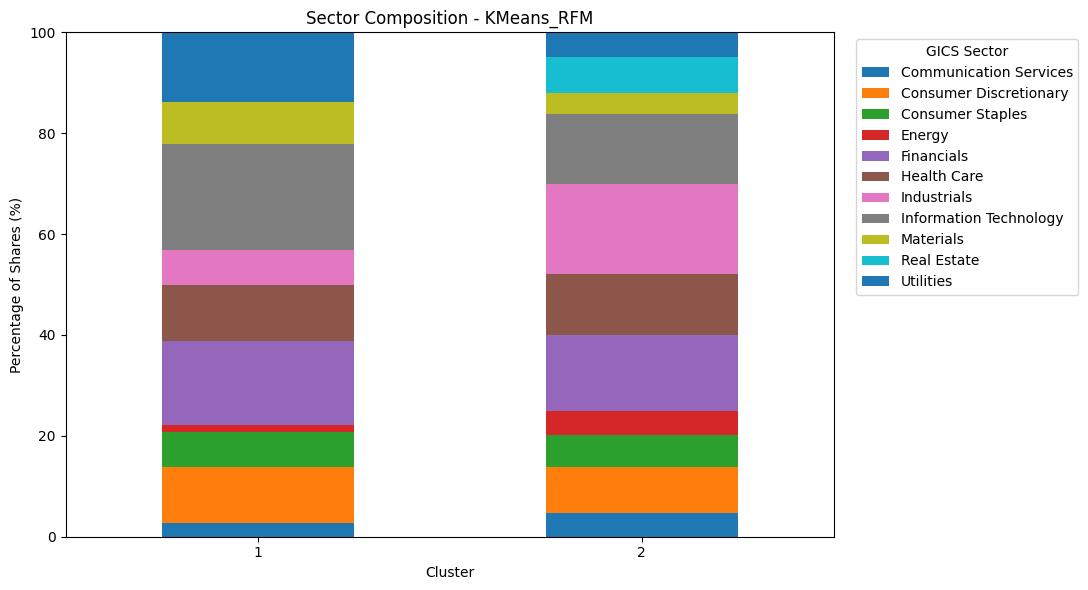

Sector composition analysis saved!


In [61]:
# TASK 3.2 - CLUSTER SECTOR COMPOSITION

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

results_dir = project_dir / "results"
figures_dir = project_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

# Load saved cluster assignments
data = pd.read_csv(
    results_dir / "final_stock_clusters.csv"
)

models = [
    "Ward_RiskReturn",
    "KMeans_RiskReturn",
    "Ward_RFM",
    "KMeans_RFM"
]

# Check required columns
assert data["Ticker"].is_unique
assert data["Sector"].notna().all()

print("TASK 3.2 - SECTOR COMPOSITION")
print("-----------------------------")
print("Total shares:", len(data))
print("Number of sectors:", data["Sector"].nunique())

for model in models:

    print(f"\nSECTOR COMPOSITION: {model}")

    # Count companies by cluster and sector
    counts = pd.crosstab(
        data[model],
        data["Sector"]
    )

    # Percentage within each cluster
    percentages = (
        counts.div(counts.sum(axis=1), axis=0)
        * 100
    )

    print("Cluster sizes:")
    display(counts.sum(axis=1).to_frame("Shares"))

    print("Sector percentages:")
    display(percentages.round(2))

    # Save tables
    counts.to_csv(
        results_dir / f"{model}_sector_counts.csv"
    )

    percentages.to_csv(
        results_dir / f"{model}_sector_percentages.csv"
    )

    # Create stacked sector composition chart
    ax = percentages.plot(
        kind="bar",
        stacked=True,
        figsize=(11, 6)
    )

    ax.set_title(f"Sector Composition - {model}")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Percentage of Shares (%)")
    ax.set_ylim(0, 100)

    ax.legend(
        title="GICS Sector",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(
        figures_dir / f"{model}_sector_composition.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("Sector composition analysis saved!")


WARD CLUSTER COMPARISON
--------------------------------
Adjusted Rand Index: 0.0226

Membership counts:


Ward_RFM,1,2
Ward_RiskReturn,,
1,61,289
2,33,115



Row percentages:


Ward_RFM,1,2
Ward_RiskReturn,,
1,17.43,82.57
2,22.30,77.70


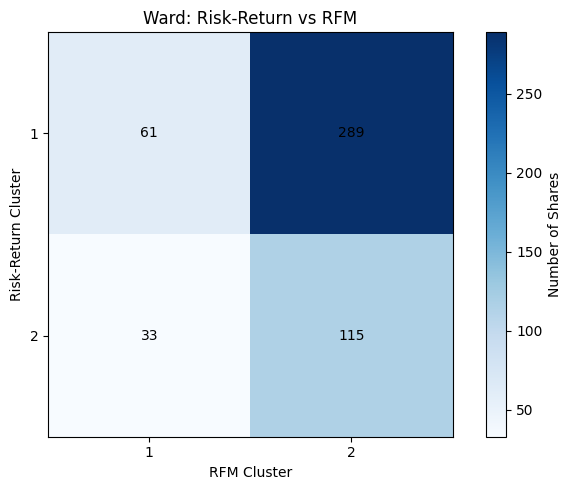


KMEANS CLUSTER COMPARISON
--------------------------------
Adjusted Rand Index: 0.0239

Membership counts:


KMeans_RFM,1,2
KMeans_RiskReturn,,
1,46,304
2,26,122



Row percentages:


KMeans_RFM,1,2
KMeans_RiskReturn,,
1,13.14,86.86
2,17.57,82.43


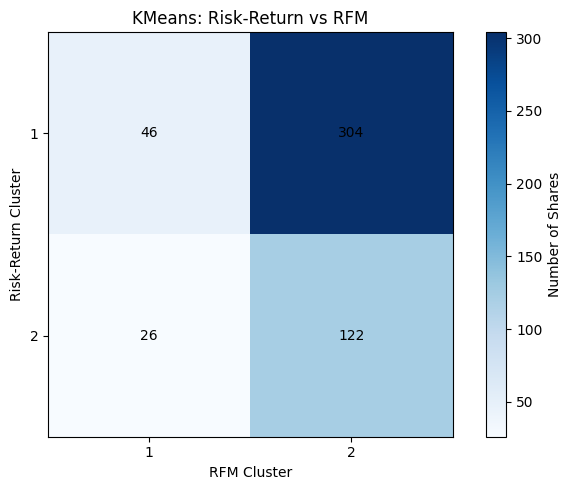


FINAL COMPARISON SUMMARY


,Algorithm,Shares,AdjustedRandIndex
0,Ward,498,0.0226
1,KMeans,498,0.0239


All comparison files saved successfully!


In [62]:
# TASK 3.2 - RISK-RETURN VS RFM COMPARISON

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

results_dir = project_dir / "results"
figures_dir = project_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

# Restore saved cluster results
data = pd.read_csv(
    results_dir / "final_stock_clusters.csv"
)

assert data["Ticker"].is_unique
assert len(data) == 498

model_pairs = {
    "Ward": ("Ward_RiskReturn", "Ward_RFM"),
    "KMeans": ("KMeans_RiskReturn", "KMeans_RFM")
}

comparison_results = []

for name, (risk_col, rfm_col) in model_pairs.items():

    # Compare cluster memberships
    table = pd.crosstab(
        data[risk_col],
        data[rfm_col]
    )

    # Percentages within each risk-return cluster
    percentages = (
        table.div(table.sum(axis=1), axis=0) * 100
    )

    # Adjusted Rand Index
    ari = adjusted_rand_score(
        data[risk_col],
        data[rfm_col]
    )

    comparison_results.append({
        "Algorithm": name,
        "Shares": len(data),
        "AdjustedRandIndex": ari
    })

    print(f"\n{name.upper()} CLUSTER COMPARISON")
    print("--------------------------------")

    print("Adjusted Rand Index:", round(ari, 4))

    print("\nMembership counts:")
    display(table)

    print("\nRow percentages:")
    display(percentages.round(2))

    # Save evidence
    table.to_csv(
        results_dir / f"{name}_risk_rfm_crosstab.csv"
    )

    percentages.to_csv(
        results_dir / f"{name}_risk_rfm_percentages.csv"
    )

    # Heatmap of membership counts
    fig, ax = plt.subplots(figsize=(7, 5))

    im = ax.imshow(table.to_numpy(), cmap="Blues")

    ax.set_xticks(range(len(table.columns)))
    ax.set_yticks(range(len(table.index)))

    ax.set_xticklabels(table.columns)
    ax.set_yticklabels(table.index)

    ax.set_xlabel("RFM Cluster")
    ax.set_ylabel("Risk-Return Cluster")
    ax.set_title(f"{name}: Risk-Return vs RFM")

    for i in range(len(table.index)):
        for j in range(len(table.columns)):
            ax.text(
                j, i,
                str(table.iloc[i, j]),
                ha="center",
                va="center",
                color="black"
            )

    plt.colorbar(im, ax=ax, label="Number of Shares")
    plt.tight_layout()

    plt.savefig(
        figures_dir / f"{name}_risk_rfm_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

comparison_summary = pd.DataFrame(comparison_results)

comparison_summary.to_csv(
    results_dir / "risk_rfm_comparison_summary.csv",
    index=False
)

print("\nFINAL COMPARISON SUMMARY")
display(comparison_summary.round(4))

print("All comparison files saved successfully!")

## Final saved-file verification

Read-only inspection and package version capture. Results are checked against the separately saved snapshot.


In [63]:
from pathlib import Path
from google.colab import drive
import pandas as pd
import numpy as np
from importlib.metadata import version, PackageNotFoundError
import sys

# Connect Google Drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

print("COURSEWORK FILE VERIFICATION")
print("=" * 45)

print("Project folder exists:", project_dir.is_dir())

# Files required for our main analysis
required_files = {
    "Ticker List": "data/sp500_tickers.csv",
    "Cleaned Historical Data":
        "data/analysis_ready_daily_prices.csv.gz",
    "Exclusion Log": "results/exclusion_log.csv",
    "Weekly Features":
        "results/weekly_return_beta_features.csv",
    "RFM Features": "results/rfm_features.csv",
    "Final Features": "results/final_stock_features.csv",
    "Risk Scaled": "results/risk_scaled.csv",
    "RFM Scaled": "results/rfm_scaled.csv",
    "Ward Evaluation":
        "results/ward_cluster_evaluation.csv",
    "K-means Evaluation":
        "results/kmeans_cluster_evaluation.csv",
    "Final Clusters":
        "results/final_stock_clusters.csv",
    "Cluster Profiles":
        "results/final_cluster_profiles.csv",
    "RFM Correlations":
        "results/rfm_correlation_matrix.csv",
    "RFM Sensitivity":
        "results/rfm_sensitivity_assignments.csv"
}

missing_files = []

print("\nFILE STATUS")
print("-" * 45)

for name, relative_path in required_files.items():

    file_path = project_dir / relative_path
    exists = file_path.is_file()

    status = "FOUND" if exists else "MISSING"

    print(f"{name}: {status}")

    if not exists:
        missing_files.append(relative_path)

# Check saved historical data batches
snapshot_folders = [
    folder for folder in (project_dir / "data").glob("*")
    if folder.is_dir()
    and list(folder.glob("batch_*.csv.gz"))
]

print("\nHistorical snapshot folders:",
      len(snapshot_folders))

# Verify feature and cluster datasets
features_file = (
    project_dir / "results" / "final_stock_features.csv"
)

clusters_file = (
    project_dir / "results" / "final_stock_clusters.csv"
)

if features_file.exists() and clusters_file.exists():

    features = pd.read_csv(features_file)
    clusters = pd.read_csv(clusters_file)

    required_columns = [
        "MeanWeeklyReturn",
        "WeeklyBeta",
        "Recency",
        "Frequency",
        "MonetaryUSD"
    ]

    model_columns = [
        "Ward_RiskReturn",
        "KMeans_RiskReturn",
        "Ward_RFM",
        "KMeans_RFM"
    ]

    feature_valid = (
        all(c in features.columns for c in required_columns)
        and np.isfinite(
            features[
                [c for c in required_columns
                 if c in features.columns]
            ].to_numpy(dtype=float)
        ).all()
    )

    print("\nFINAL DATASET CHECK")
    print("-" * 45)

    print("Feature records:", len(features))
    print("Cluster records:", len(clusters))

    print("Matching share sets:",
          set(features["Ticker"]) == set(clusters["Ticker"]))

    print("Unique feature tickers:",
          features["Ticker"].is_unique)

    print("All five features valid:", feature_valid)

    print("Four clustering columns present:",
          all(c in clusters.columns
              for c in model_columns))

    print("Missing cluster assignments:",
          clusters[
              [c for c in model_columns
               if c in clusters.columns]
          ].isna().sum().sum())

# Verify saved figures
figures_dir = project_dir / "figures"

figures = list(figures_dir.glob("*.png"))

print("\nFIGURE VERIFICATION")
print("-" * 45)

print("Total saved PNG figures:", len(figures))

for figure in sorted(figures):
    print(figure.name)

# Save package versions for reproducibility
packages = [
    "pandas", "numpy", "yfinance",
    "scipy", "scikit-learn",
    "matplotlib", "seaborn",
    "requests", "lxml"
]

requirements = []

for package in packages:
    try:
        requirements.append(
            f"{package}=={version(package)}"
        )
    except PackageNotFoundError:
        print("Package unavailable:", package)

requirements_file = project_dir / "requirements.txt"

requirements_file.write_text(
    "\n".join(requirements) + "\n"
)

print("\nENVIRONMENT")
print("-" * 45)

print("Python:", sys.version.split()[0])
print("Package versions saved:", requirements_file.exists())

print("\nFINAL CHECK SUMMARY")
print("-" * 45)

print("Missing files:", len(missing_files))

if missing_files:
    print("Files requiring investigation:")
    for filename in missing_files:
        print("-", filename)
else:
    print("All listed files were found!")

print("\nFile verification finished.")


COURSEWORK FILE VERIFICATION
Project folder exists: True

FILE STATUS
---------------------------------------------
Ticker List: FOUND
Cleaned Historical Data: FOUND
Exclusion Log: FOUND
Weekly Features: FOUND
RFM Features: FOUND
Final Features: FOUND
Risk Scaled: FOUND
RFM Scaled: FOUND
Ward Evaluation: FOUND
K-means Evaluation: FOUND
Final Clusters: FOUND
Cluster Profiles: FOUND
RFM Correlations: FOUND
RFM Sensitivity: FOUND

Historical snapshot folders: 1

FINAL DATASET CHECK
---------------------------------------------
Feature records: 498
Cluster records: 498
Matching share sets: True
Unique feature tickers: True
All five features valid: True
Four clustering columns present: True
Missing cluster assignments: 0

FIGURE VERIFICATION
---------------------------------------------
Total saved PNG figures: 18
KMeans_RFM_clusters.png
KMeans_RFM_sector_composition.png
KMeans_RiskReturn_clusters.png
KMeans_RiskReturn_sector_composition.png
KMeans_risk_rfm_comparison.png
Ward_RFM_clusters.

### Re-open the saved fixed analysis dataset (read-only)


In [64]:
# STEP 16.3.3 - LOAD SAVED HISTORICAL DATA

import pandas as pd
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/CRM_CWK1_2026"
)

# Saved analysis dataset
price_file = (
    project_dir / "data" /
    "analysis_ready_daily_prices.csv.gz"
)

# Original acquisition log
log_file = (
    project_dir / "data" /
    "20261111_102754_UTC" /
    "download_log.csv"
)

# Load saved files
saved_prices = pd.read_csv(price_file)
saved_log = pd.read_csv(log_file)

print("SAVED DATA VERIFICATION")
print("-----------------------")

print("Historical rows:", len(saved_prices))
print("Unique symbols:",
      saved_prices["Ticker"].nunique())

print("Download log records:", len(saved_log))

print("\nDownload status:")
display(saved_log["Status"].value_counts())

print("\nSample historical data:")
display(saved_prices.head())

print("\nSaved data loaded successfully!")


SAVED DATA VERIFICATION
-----------------------
Historical rows: 501495
Unique symbols: 499
Download log records: 504

Download status:


,count
Status,
Downloaded,499
Review,5



Sample historical data:


,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Ticker
0,2021-01-04,146.321075,147.324417,142.600327,143.704010,117.860252,3583455.0,0.0,0.0,MMM
1,2021-01-05,143.821075,144.857864,142.683945,143.461533,117.661430,2745179.0,0.0,0.0,MMM
2,2021-01-06,144.414719,146.797653,143.846161,145.643814,119.451233,4002294.0,0.0,0.0,MMM
3,2021-01-07,143.444809,145.033447,138.929764,141.906357,116.385925,7012626.0,0.0,0.0,MMM
4,2021-01-08,141.446487,141.755859,137.633774,139.314377,114.260101,5750488.0,0.0,0.0,MMM



Saved data loaded successfully!
